# **Artificial Intelligence & Machine Learning (ST1511) CA2 Part B:**
### **Name: Cayden Sim**
### **Student ID: P2510893**
### **Class: DAAA/FT/1B/01**


---

## **Background Overview:**
- 397 days of data on energy consumption was collected. With each date representing the first day of each month from 1990 to 2022.
- The data includes:
    - Date
    - Gas Consumption (tons)
    - Electricity Consumption (MWh)
    - Water Consumption (tons)

## **Planned Workflow:**
-  ### Oveerall Workflow includes:
    - Data Exploration (EDA)
        - Understand data distribution, patterns and relationships
        - Identify potential outliers/anomalies
    - Preprocessing
        - Handle any missing values
        - Feature Engineering
    - Model Building and Implementation
        - Implement various models from Statsmodel library
    - Evaluation
        -  Model Comparison
            - Compare results across multiple forecasting models
            - Determine most suitable model that achieves the best results
    - Hyperparameter Tuning:
        - After finalising the model to use, conduct hyperparameter tuning in order to get the most optimal parameters that result in the most optimal results.


- ### **Libraries Used:**
    - **Data Manipulation & Numerical Operation**
        - pandas
        - numpy
    - **Machine Learning:**
        - statsmodel
    - **Data Visualization**
        - matplotlib
        - Seaborn


## **Ultimate End Goal:**
The ultimate goal of this project is to forecast the total energy consumption (gas, electricity & water) for the next 60 months via training time series models




---
## **Step 1:** Importing Necessary Libraries and Modules

- Importing the required libraries as well as modules that are going to be used in this project.

In [1]:
# %pip install pmdarima

- Auto-ARIMA requires the external `pmdarima` library, which is installed separately to enable automated hyperparameter selection for ARIMA-based models.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.model_selection import TimeSeriesSplit
import itertools
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')


- Libraries added include:
    - pandas
    - numpy
    - matplotlib
    - seaborn
- **pandas** and **numpy** are used for data handling and analysis.
- **matplotlib** and **seaborn** are used to display visuals and graphs.

--- 
## **Step 2:** Loading Dataset's CSV File

- Import the downloaded dataset from the file explorer.

In [3]:
energy_df = pd.read_csv("C:/Users/nedya/OneDrive/Desktop/AIML/CA2/CA2 Datasets/CA2-Energy-Consumption-Data.csv")

- Energy Consumption Data dataset is imported via pandas' **`.read_csv()`** method.
- Dataset is stored into a variable **`'energy_df'`**.

--- 
## **Step 3:** Exploratory Data Analysis **(EDA)**

- ### **Planned Overview**: 
    - Showcase dataset's information.

    - Check for missing data in columns. 

    - Identifying major outliers that can affect the output of the machine.

    - Visualize data spread with graphs.

    - Identify any trend/seasonality via seasonal decomposition graph.

In [4]:
print("Here is a quick look at the DataFrame:")
energy_df

Here is a quick look at the DataFrame:


,DATE,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
0,1/1/1990,18.0,725.1,548.8
1,1/2/1990,15.8,706.7,640.7
2,1/3/1990,17.3,624.5,511.1
3,1/4/1990,18.9,574.7,515.3
4,1/5/1990,22.0,553.2,488.4
...,...,...,...,...
392,1/9/2022,27.7,986.2,513.3
393,1/10/2022,31.8,936.1,373.1
394,1/11/2022,31.0,973.4,343.9
395,1/12/2022,32.4,1147.2,348.3


- Here is how the DataFrame of energy consumption data looks like.

In [5]:
print("Here is the shape of the DataFrame: ", energy_df.shape)
energy_df.info()

Here is the shape of the DataFrame:  (397, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   DATE                           397 non-null    object 
 1   Gas Consumption (tons)         397 non-null    float64
 2   Electricity Consumption (MWh)  397 non-null    float64
 3   Water Consumption (tons)       397 non-null    float64
dtypes: float64(3), object(1)
memory usage: 12.5+ KB


- Using the **`.shape`** attribute and printing it shows that the customer dataset has **397 rows** and **4 columns**.
- Using the **`.info()`** method on the DataFrame prints its information.
    - From the output, it is shown that all rows are **`non-null`**, indicating that there are no empty data cells.
    - **`dtype`** shows the types of data in each column.

In [6]:
print("DataFrame Description:")
energy_df.describe()

DataFrame Description:


,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
count,397.000000,397.000000,397.000000
mean,23.785139,888.472544,484.953652
std,4.903452,153.877594,133.908863
min,11.600000,553.200000,44.400000
25%,20.200000,771.100000,384.400000
50%,23.500000,897.800000,487.400000
75%,27.900000,1005.200000,580.200000
max,46.000000,1294.000000,811.000000


- The **`describe()`** summary provides an overview of key statistical properties such as the mean, standard deviation, and minimum/maximum values for each numerical feature. 

In [7]:
energy_df.isnull().sum()

DATE                             0
Gas Consumption (tons)           0
Electricity Consumption (MWh)    0
Water Consumption (tons)         0
dtype: int64

- Using the pandas' **'.isnull()'** method together with the **'.sum()'** method, it computes the total number of empty values within each column.
- The output above shows that all columns **'.isnull().sum()'** equate to **0**, indicating that there are no missing values in each column.

---
## **Step 3.5 - Continutinuation of EDA:** Plotting Visuals (KIV Seasonal Decomposition)

- Some visuals will be plotted for better visualization and analysis of the original features.
- These visuals represents the relationship of each feature with another.

### **Mini Conversion Step:** Converting Data Column to Datetime Format **(Pre-Preprocessing)**
- Before we plot the visuals, convert the date column into a datetime format and set the index.
- This ensures that the dataset is treated as a proper time series.

In [8]:
energy_df['DATE'] = pd.to_datetime(energy_df['DATE'], format ='%d/%m/%Y')
energy_df = energy_df.sort_values('DATE').set_index('DATE')


energy_df

,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
DATE,,,
1990-01-01,18.0,725.1,548.8
1990-02-01,15.8,706.7,640.7
1990-03-01,17.3,624.5,511.1
1990-04-01,18.9,574.7,515.3
1990-05-01,22.0,553.2,488.4
...,...,...,...
2022-09-01,27.7,986.2,513.3
2022-10-01,31.8,936.1,373.1
2022-11-01,31.0,973.4,343.9


- Use pandas' '.to_datetime()' function to convert the dates in the DATE column into the datetime format. 
- After that, use .sort_values() and .set_index() and place 'DATE' inside the parenthesis.
- This ensures that the dates are ordered chronologically.
- This allows for easier graph plotting in the EDA portion.

**Not Preprocessing

## **Visual Representation 1: Histogram**

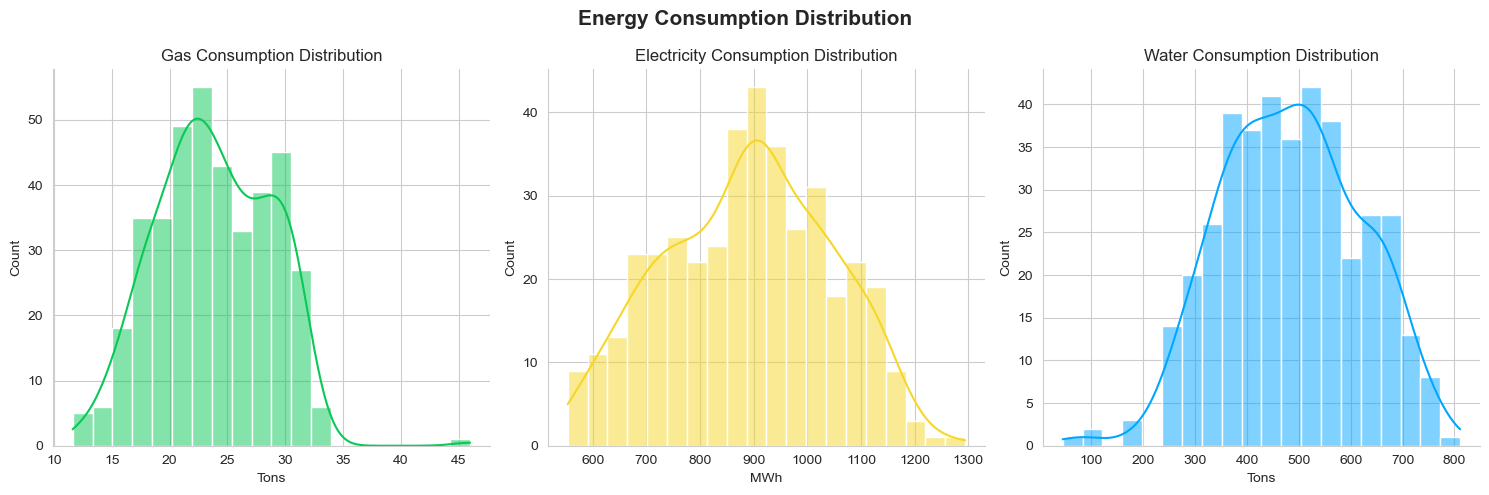

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.histplot(energy_df['Gas Consumption (tons)'], bins=20, ax=axes[0], kde=True, color="#09C856")
axes[0].set_title('Gas Consumption Distribution')
axes[0].set_xlabel('Tons')
axes[0].grid(True)

sns.histplot(energy_df['Electricity Consumption (MWh)'], bins=20, ax=axes[1], kde=True, color="#F6D728")
axes[1].set_title('Electricity Consumption Distribution')
axes[1].set_xlabel('MWh')
axes[1].grid(True)

sns.histplot(energy_df['Water Consumption (tons)'], bins=20, ax=axes[2], kde=True, color="#00A6FF")
axes[2].set_title('Water Consumption Distribution')
axes[2].set_xlabel('Tons')
axes[2].grid(True)

plt.suptitle('Energy Consumption Distribution', fontsize=15, fontweight='bold')
plt.tight_layout()
sns.despine()
plt.show()






### **Key Insights:**
- The subplots of histograms illustrate the distribution of energy consumption for gas, electricity and water respectively, highlighting the differences in spread and skewness that was observed in the line chart.

- Skewness:
    - Gas consumption displays a right-skewed distribution, with most observations being concentrated between 20 to 30 tons. and a small number of higher value observation that extend the right tail like the 45 ton indicator on the far right.
    
    - Electricity consumption shows a more moderate right skew but resembles a normally distributed graph due to the exhibition of an almost symmetry-like shape between the left and right sides of the graph as well as its peak being in the centre of the data distribution.
        - Majority of the data is clustered around 800 to 1000 MWh, while there are fewer observations that have higher consumption above 1100Mwh as well as some observations that have a lower consumption than 800 MWh.
    
    - Water consumption exhibits a more left-skewed distribution, with more observations being on the right side of the graph, ranging from about 400 to 700 tons, with fewer observations on the left side that have a lower consumption than 300 tons.
        - Shows that lower water consumption is less frequent but still present.

    - The presence of right-skewness in gas and electricity consumption suggests that mean values may be influenced by higher consumption periods and vice versa for water consumption.

## **Visual Representation 2:** Boxplot

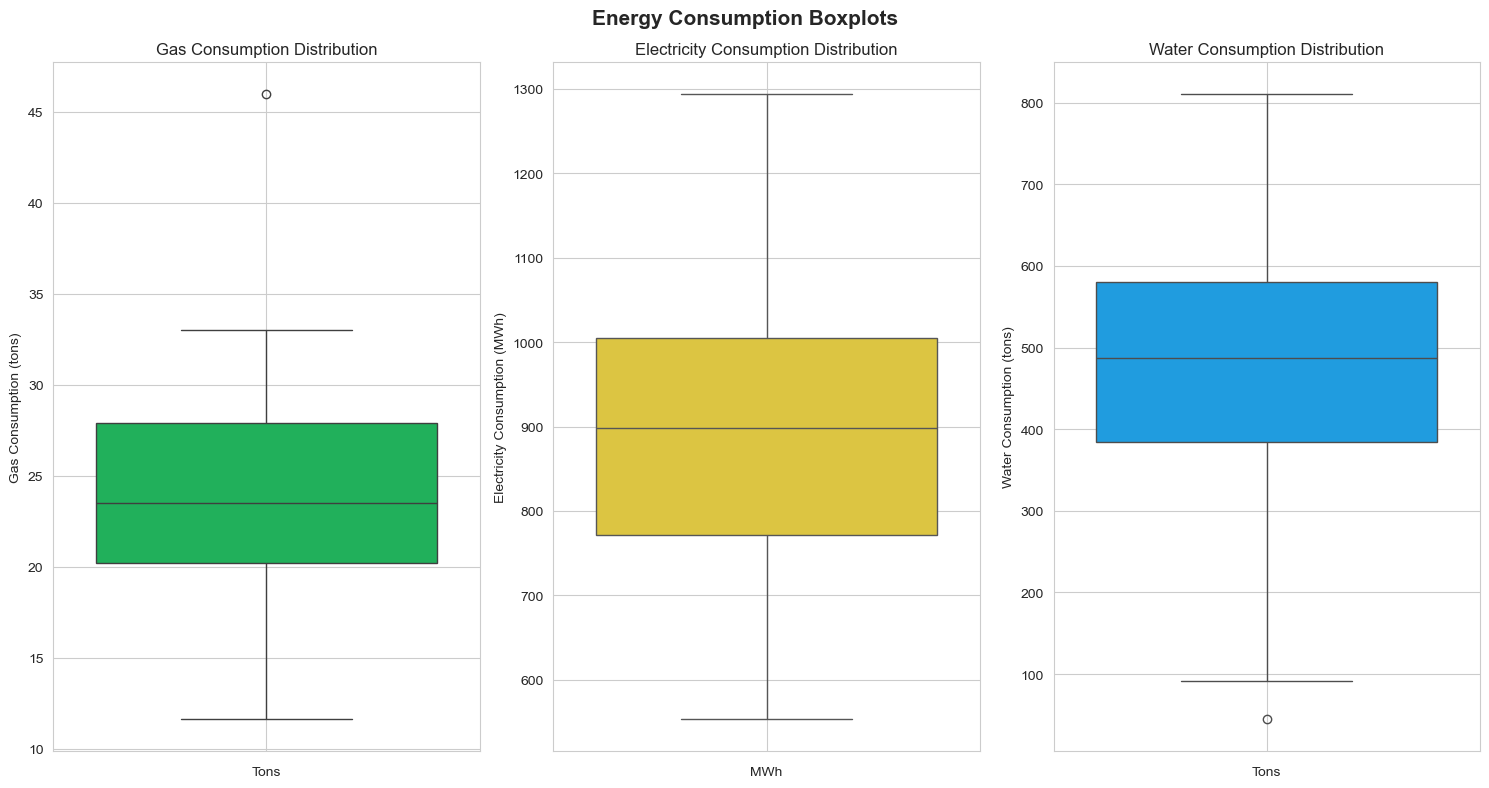

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 8))

sns.boxplot(y=energy_df['Gas Consumption (tons)'], ax=axes[0], color='#09C856')
axes[0].set_title('Gas Consumption Distribution')
axes[0].set_xlabel('Tons')
axes[0].grid(True)

sns.boxplot(y=energy_df['Electricity Consumption (MWh)'], ax=axes[1], color='#F6D728')
axes[1].set_title('Electricity Consumption Distribution')
axes[1].set_xlabel('MWh')
axes[1].grid(True)

sns.boxplot(y=energy_df['Water Consumption (tons)'], ax=axes[2], color='#00A6FF')
axes[2].set_title('Water Consumption Distribution')
axes[2].set_xlabel('Tons')
axes[2].grid(True)

plt.suptitle('Energy Consumption Boxplots', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()






### **Key Insights:**
These boxplots provide additional insights about the features that were not covered by the histograms.

- ### **Gas:** 
    - The median of gas consumption is closer to Q1 than it is to Q3, indicating that more data is concentrated on the lower side.
    - There is also an outlier at >45 tons, approximately 46-47 tons. Because of this outlier, it extends the right tail, causing the mean to be higher than the median, resulting in a right skew.

- ### **Electricity:**
    - Median is near the centre of the box, almost symmetrical.
    - Exhibits a wider interquartile range, illustrating a higher variability of the data.
    - The whiskers are relatively almost balanced, with the right tail being a little longer, hence it results in the moderate right-skewness of the distribution.
    - There are also no extreme outliers.
    - Indicates that electricity consumption is quite stable with minimal fluctuations, supporting the line chart.

- ### **Water:**
    - Median is slightly closer to Q3 than Q1, indicating that more data is concentrated on the upper side of the distribution.
    - The lower whisker/tail is longer than the upper one, with an anomaly on the lower side, <100 tons.
    - The presence of the anomaly on the lower bound brings the mean down, making it smaller than the median, resulting in a left skew.

- Overall, the spread of electricity and water consumption are much wider than that of gas consumption. Suggesting that the consumption of electricity and water is much wider and spread out, convering a larger numerical range than gas consumption.
    - Showing that there is a greater variance in these 2 energy sources due to the many diverse way they could be used.

## **Visual Representation 3: Decomposition Plot:**

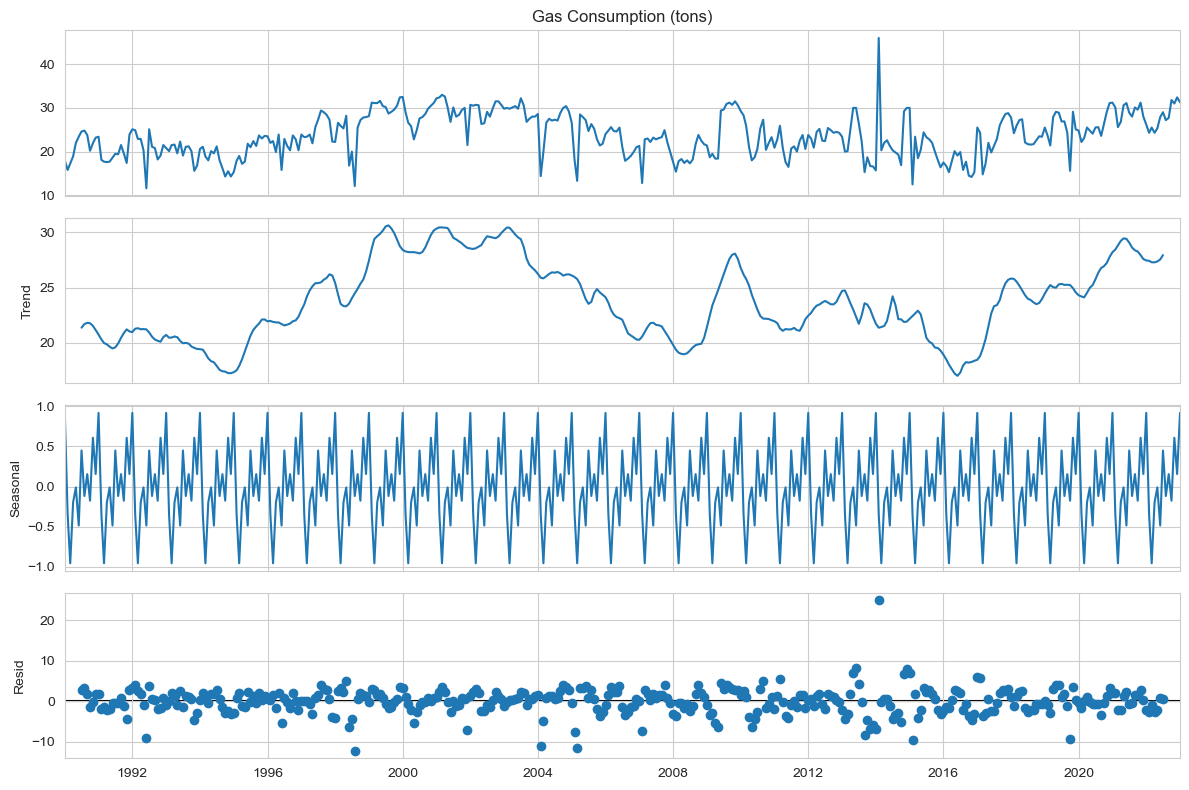

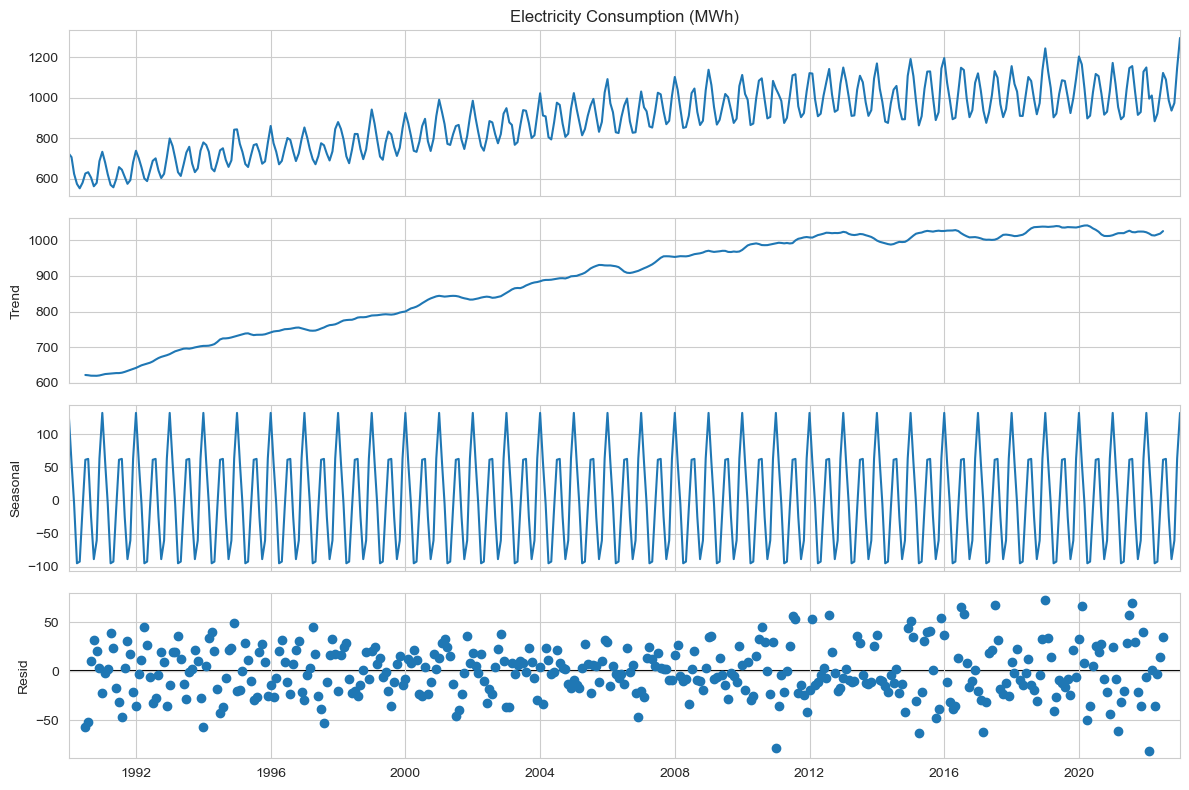

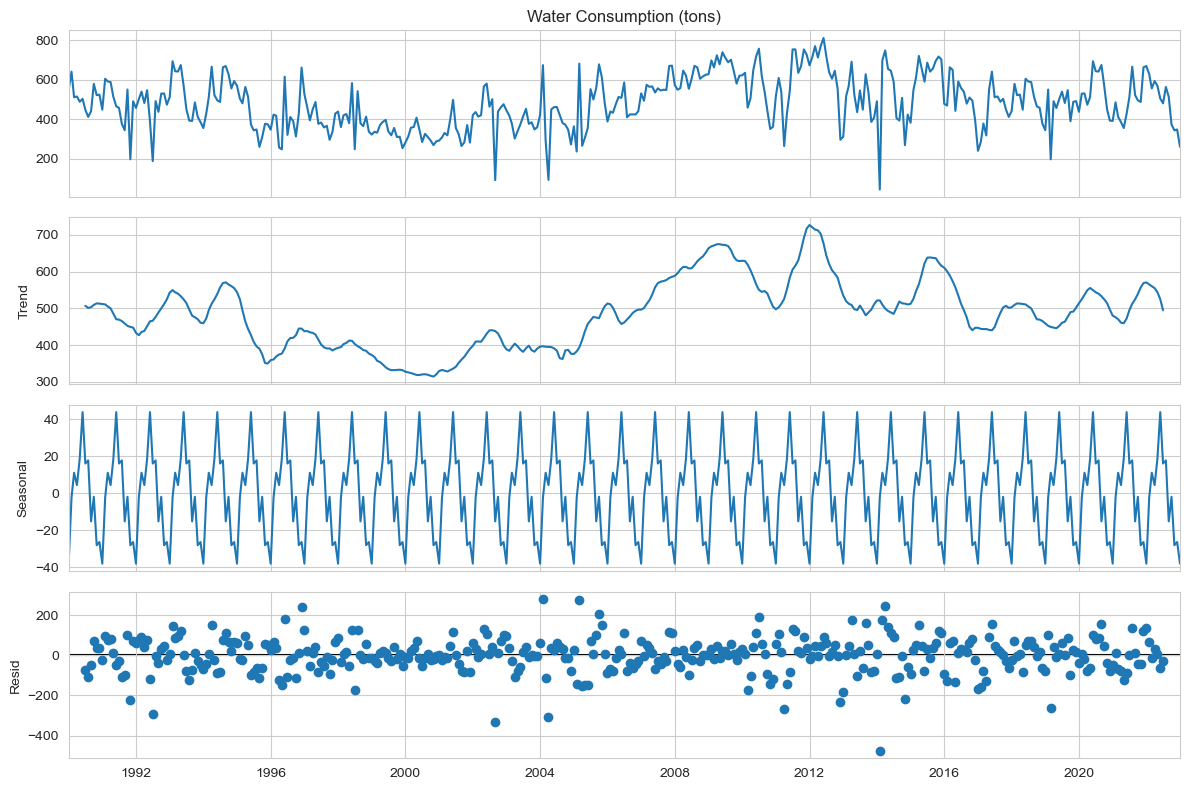

In [11]:
gas_results = seasonal_decompose(energy_df['Gas Consumption (tons)'], model='additive', period=12)

fig = gas_results.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()


electricity_results = seasonal_decompose(energy_df['Electricity Consumption (MWh)'], model='additive', period=12)
fig = electricity_results.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

water_results = seasonal_decompose(energy_df['Water Consumption (tons)'], model='additive', period=12)
fig = water_results.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()







### **Key Insights (Seasonal Decomposition):**

 The seasonal decomposition plots separate each energy series into observed, trend, seasonal, and residual components, providing deeper insight into their underlying structure.

- **Gas consumption:**
    - The trend component shows a gradual upward movement with moderate fluctuations, indicating a slow but steady increase in long-term usage. The seasonal component exhibits a stable and repeating annual pattern, while the residuals capture short-term irregular variations, including a notable spike corresponding to an unusually high consumption period.

- **Electricity consumption:**
    - Displays a strong and consistent upward trend, confirming long-term growth in electricity demand. Its seasonal component is highly regular and pronounced, indicating a clear yearly cycle. The residuals show moderate variability, suggesting that most systematic patterns are well explained by the trend and seasonal components.

- **Water consumption:**
    - Shows a more irregular trend pattern, with periods of increase followed by decline, reflecting changing long-term usage behaviour. The seasonal component remains relatively stable across years, while the residuals exhibit higher variability and occasional extreme deviations, indicating greater short-term unpredictability.

Overall, the decomposition confirms that all three series contain both trend and seasonal components, supporting the use of additive seasonal models. The presence of strong seasonality and long-term trends further justifies the application of SARIMA models with internal differencing for forecasting.

---
## **Step 4:** Preprocessing and Feature Engineering
- Check stationarity of all 3 energy types via **`Augmented Dickey Fuller`** (ADF) Test.

- Assuming the status quo/null hypothesis is that the 3 energy consumption types are non-stationary and the alternative hypothesis is that the 3 energy consumptions types are stationary.

- If the resulting **`p-value`** is **`>0.05`**, we **`do not reject`** the **`null hypothesis`** and hence the consumption types are **`non-stationary`**.
    - If **`non-stationary`**, have to **`conduct differencing`** then re-run ADF test.

- If resuling **`p-value`** is **`<0.05`**, then **`reject`** the **`null hypothesis`** and hence the energy consumptions types are **`stationary`**.
    - **`Differencing`** is **`not required`**.

## **Step 4.1:** Checking for Stationarity
In this part, the stationarity of the consumption of the 3 energy sources will be checked via the visual test (plotting graphs), and later confirmed via the **`Augmented Dickey Fuller (ADF)`** Test.

### **Visual Test:**
- The visual test aims to justify the stationarity of the 3 energy sources' consumption, so that we roughly know which sources to perform differencing later on.

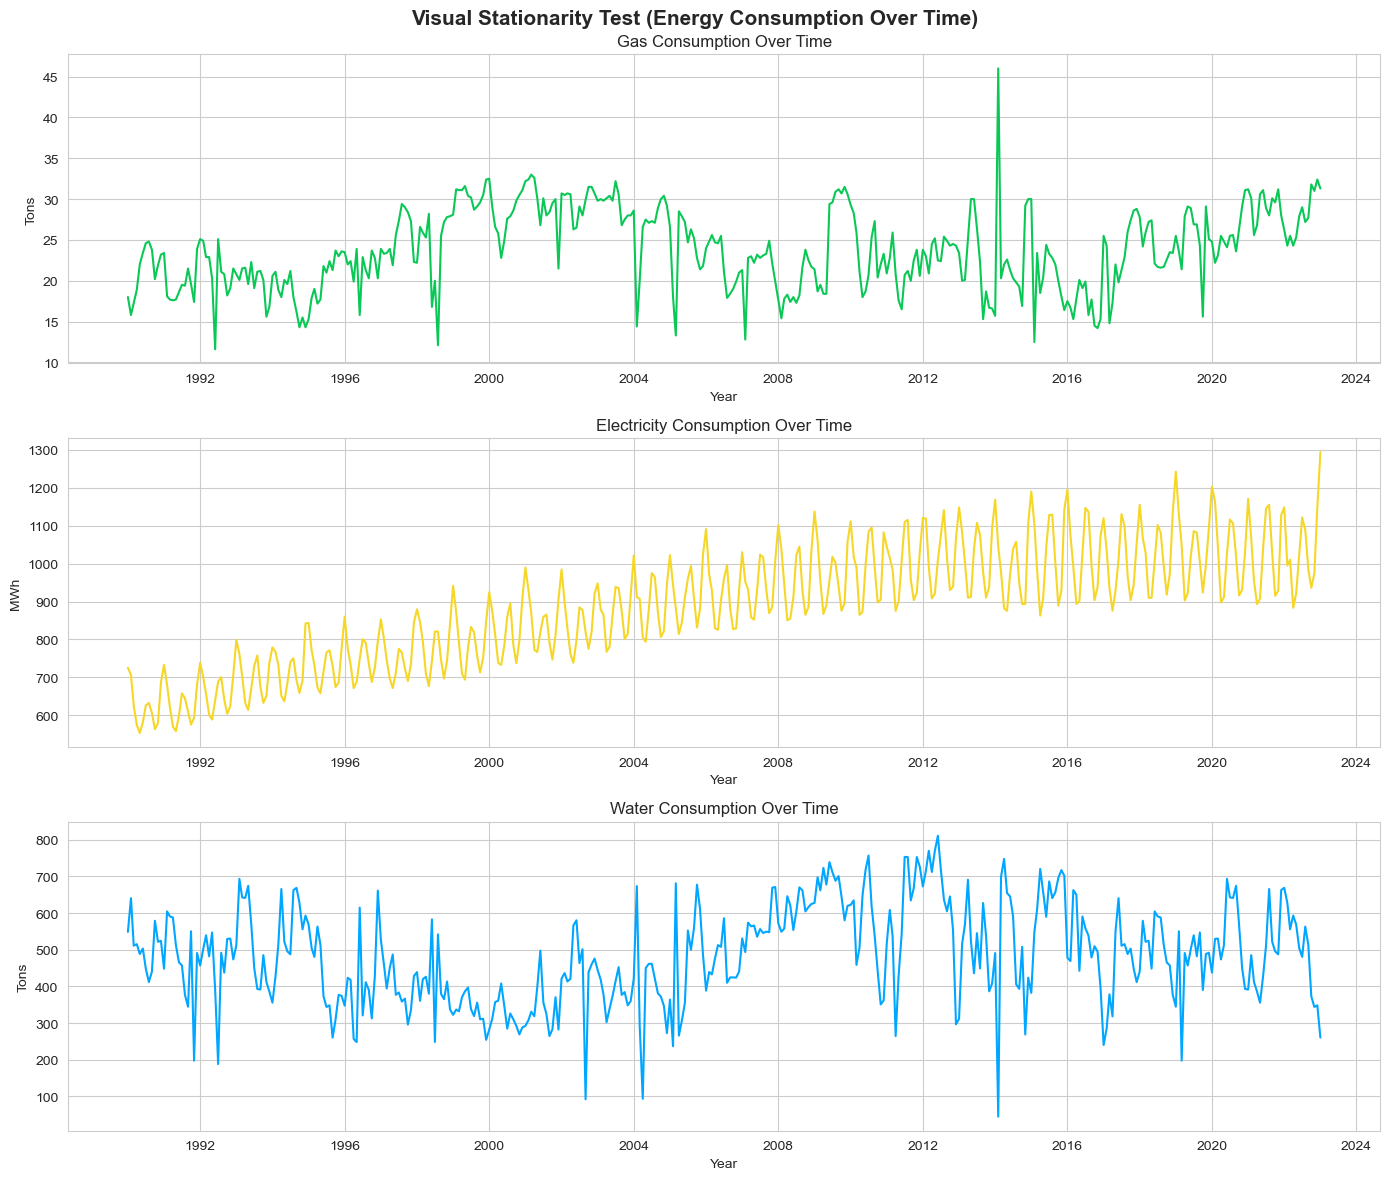

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes[0].plot(energy_df.index, energy_df['Gas Consumption (tons)'], color='#09C856')
axes[0].set_title('Gas Consumption Over Time')
axes[0].set_ylabel('Tons')
axes[0].set_xlabel('Year')
axes[0].grid(True)

axes[1].plot(energy_df.index, energy_df['Electricity Consumption (MWh)'], color='#F6D728')
axes[1].set_title('Electricity Consumption Over Time')
axes[1].set_ylabel('MWh')
axes[1].set_xlabel('Year')
axes[1].grid(True)

axes[2].plot(energy_df.index, energy_df['Water Consumption (tons)'], color='#00A6FF')
axes[2].set_title('Water Consumption Over Time')
axes[2].set_ylabel('Tons')
axes[2].set_xlabel('Year')
axes[2].grid(True)

plt.suptitle('Visual Stationarity Test (Energy Consumption Over Time)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()






### **Key Insights:**
- This subplot of line chart illustrates the long term consumption of gas, electricity and water over time respectively.
- This line chart subplot goes more in depth into the observed trend from the decomposition plot above.

- There is a net increase overall for both gas and electricity consumption.
    - Gas consumption shows a gradual upward trend with moderate fluctuations, increasing from roughly 18–20 tons in the early 1990s to around 30+ tons by 2023, indicating a steady rise in usage over time.
    - Electricity consumption exhibits the strongest and most consistent upward trend, rising from approximately 700 MWh in 1990 to about 1300 MWh in 2023, suggesting increasing dependence on electricity over the years.

- In contrast, there is an overall net decline in water consumption from 1990 to 2023.
    - Decreasing from around 500 tons in 1990 to approximately 250–300 tons by 2023, despite noticeable short-term variability.

- Compared to gas and electricity, water consumption displays higher volatility, indicating greater short-term fluctuations and less stable usage patterns. (more messy patterns)

### **Justification:**
- The presence of clear trends and visible seasonal fluctuations across all three series indicates that the data is non-stationary, as the mean and variability are not constant over time. These observations justify the need for formal stationarity testing and the use of differencing within time series models which will be incorporated later.

### **ADF Test:**
The Augemted Dickey Fuller (ADF) Test serves as a confirmatory test, it is used to determine whether the series is stationary or not using **`Hypothesis Testing`** in Statistics.

- ### **The Null Hypothesis: (Status Quo)**
    - The series is **non-stationary**.

- ### **The Alternative Hypothesis:**
    - The series is **stationary**.


The ADF Test handles P-value calculation, which will be the metric used to determine which hypothesis we reject. 
- Using a significance level of **`5% (0.05)`**:
    - If **`P > 0.05`**, it is not rare for a pattern of non-stationarity to occur by random chance, if the series is assumed to be non-stationary. Because the observed data is not rare under the assumption of the null hypothesis, the null hypothesis will **`NOT`** be rejcted and series is stationary.
    
    - If **`P < 0.05`**, then it is rare to observe a pattern of non-stationarity if the series is assumed to be non-stationary. Since the data is rare, we assume that a rare event did not occur by chance. Therefore, the null hypothesis will be **`rejected`** and the alternative hypothesis will be taken instead.


#### **Step 4.1.1:** Double Checking Stationarity of Gas Consumption

In [13]:
adftestGas = adfuller(energy_df['Gas Consumption (tons)'])
print('Number of Observations:', adftestGas[3], '\np-value:', round(adftestGas[1], 2))

Number of Observations: 390 
p-value: 0.01


#### **Step 4.1.2:** Double Checking Stationarity of Electricity Consumption

In [14]:

adftestElec = adfuller(energy_df['Electricity Consumption (MWh)'])
print('Number of Observations:', adftestElec[3], '\np-value:', round(adftestElec[1], 2))

Number of Observations: 381 
p-value: 0.19


#### **Step 4.1.3:** Double Checking Stationarity of Water Consumption

In [15]:
adftestWater = adfuller(energy_df['Water Consumption (tons)'])
print('Number of Observations:', adftestWater[3], '\np-value:', adftestWater[1])

Number of Observations: 392 
p-value: 8.984549388336955e-05


### **What Can Be Concluded:**
- **The results are as shown above:**
    - **`Gas Consumption`** with a P-value of **`0.01`** (2 d.p)
    
    - **`Electricity Consumption`** with a P-value of **`0.19`** (2 d.p)
    
    - **`Water Consumption`** with a P-value of **`8.98 × 10⁻⁵`**, which can be **`taken as 0.00`** (2.d.p).

- **Takeaways:**
    - Although it is justified in the visual test that the consumption of all energy types are non-stationary, the ADF Test proves it wrong.
    
    - Despite their trends, **`Gas and Water Consumptions`** are actually **`stationary`**, with P-values of **`less than 0.05`**, making it a **`rare`** case to obtain a non-stationary pattern if the assumed null hypothesis is true. Hence, the **`null hypothesis`** (They are non-stationary) will be **`rejected`**.
    
    - From the graph above, the trend of electricity is far more obvious than water and gas due to their fluctuations whereas electricity shows a clear upward trend with minimal fluctuations. Hence, the **`P-value is > 0.05`** and therefore **`null hypothesis`** will **`NOT`** be rejected and the consumption of electricity is **`non-stationary`**.
    

## **Step 4.2:** Feature Engineering
- New Columns will be added.
- Implement Simple Moving Average, and store values in 2 separate columns.

In [16]:

energy_df['Gas_SMA_6'] = energy_df['Gas Consumption (tons)'].rolling(window=6).mean()
energy_df['Gas_SMA_12'] = energy_df['Gas Consumption (tons)'].rolling(window=12).mean()

energy_df['Electricity_SMA_6'] = energy_df['Electricity Consumption (MWh)'].rolling(window=6).mean()
energy_df['Electricity_SMA_12'] = energy_df['Electricity Consumption (MWh)'].rolling(window=12).mean()

energy_df['Water_SMA_6'] = energy_df['Water Consumption (tons)'].rolling(window=6).mean()
energy_df['Water_SMA_12'] = energy_df['Water Consumption (tons)'].rolling(window=12).mean()

energy_df['Gas_Seasonal_Diff'] = energy_df['Gas Consumption (tons)'].diff(12)
energy_df['Elec_Seasonal_Diff'] = energy_df['Electricity Consumption (MWh)'].diff(12)
energy_df['Water_Seasonal_Diff'] = energy_df['Water Consumption (tons)'].diff(12)


energy_df = energy_df.dropna()
energy_df

,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons),Gas_SMA_6,Gas_SMA_12,Electricity_SMA_6,Electricity_SMA_12,Water_SMA_6,Water_SMA_12,Gas_Seasonal_Diff,Elec_Seasonal_Diff,Water_Seasonal_Diff
DATE,,,,,,,,,,,,
1991-01-01,23.4,733.1,448.4,22.883333,21.608333,633.616667,622.325000,487.666667,502.750000,5.4,8.0,-100.4
1991-02-01,18.1,679.9,604.7,21.766667,21.800000,641.516667,620.091667,519.833333,499.750000,2.3,-26.8,-36.0
1991-03-01,17.7,622.2,591.0,20.750000,21.833333,644.250000,619.900000,544.866667,506.408333,0.4,-2.3,79.9
1991-04-01,17.6,570.3,588.0,20.316667,21.725000,645.433333,619.533333,546.366667,512.466667,-1.3,-4.4,72.7
1991-05-01,17.7,558.1,513.0,19.616667,21.366667,641.783333,619.941667,544.916667,514.516667,-4.3,4.9,24.6
...,...,...,...,...,...,...,...,...,...,...,...,...
2022-09-01,27.7,986.2,513.3,26.900000,27.183333,1003.800000,1012.341667,537.316667,560.191667,-2.4,-41.4,-8.5
2022-10-01,31.8,936.1,373.1,28.150000,27.366667,1012.566667,1014.108333,500.650000,549.983333,2.2,21.2,-122.5
2022-11-01,31.0,973.4,343.9,29.100000,27.350000,1021.333333,1017.816667,463.100000,538.025000,-0.2,44.5,-143.5


### **Simple Moving Average (SMA) — Electricity, Gas, Water**

- **Why 6 and 12?**
    - I used 6 because it represents taking the **`half-year`** moving average.
    - Likewise for 12, it represents taking **`full-year`** moving average (12 Months).

- After that, I dropped the rows whose SMA 6 and 12 Score was **`NaN`**.



### **Seasonal Differencing — Electricity, Gas, Water**

- **What is Seasonal Differencing?**
    - Seasonal differencing removes recurring seasonal patterns from time series data by comparing each period to the same period in the previous cycle. This transformation helps make the data stationary—a key requirement for many forecasting models.

To reduce yearly seasonality in this monthly dataset, seasonal differencing is applied using **`.diff(12)`** for each series.

- **Why `diff(12)`?**  
  Because the data is monthly, **12 periods = 12 months = 1 year**.  
  - **`.diff(12)`** computes:  **[y'_t = y_t - y_{t-12}]**
    - This compares each month to the **same month in the previous year**, helping remove repeating annual cycles and making the series more suitable for ACF/PACF and SARIMA-style modelling.

- **Why `dropna()`?**  
  The first **12 rows** become **`NaN`** because there is no earlier year to subtract from (no \(y_{t-12}\)).  


### **Justification For Dropping `NaN` Rows:**

- Although dropping them means losing data, I feel that it is still acceptable just because of the fact that the rows that were dropped were from 1990, which is the very first year featured in this dataset.
    - I think that since it is the first year, the data represented would be the oldest, and realistically, energy consumption has increased significantly over time. Hence, I think the data represented by 1990 is too old and unreliable, hence it might not be a meaningful representation in making useful predictions of future years. Therefore, I am dropping them.

## **Step 4.3:** SMA Plotting
- Plot and compare the original energy consuption to the moving averaged version.

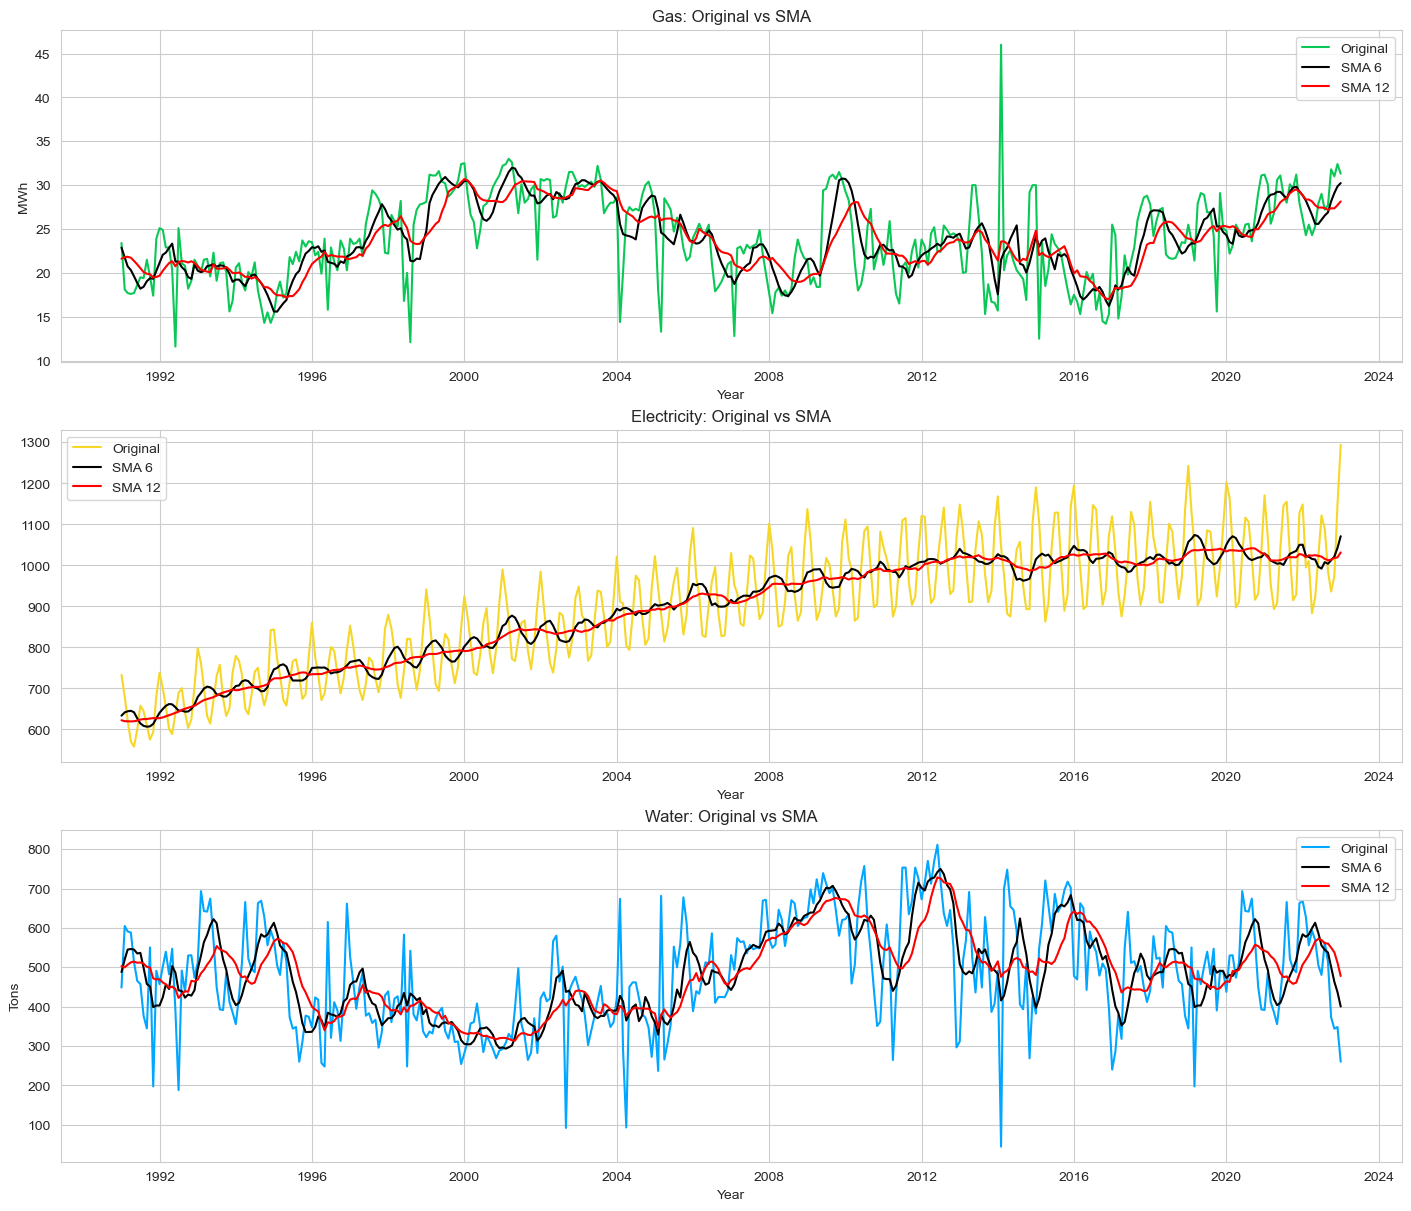

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), constrained_layout=True)

axes[0].plot(energy_df.index, energy_df['Gas Consumption (tons)'], label="Original", color='#09C856')
axes[0].plot(energy_df.index, energy_df['Gas_SMA_6'], label="SMA 6", color='black')
axes[0].plot(energy_df.index, energy_df['Gas_SMA_12'], label="SMA 12", color='#ff0000')
axes[0].set_xlabel('Year')
axes[0].set_ylabel("Tons")
axes[0].set_title("Gas: Original vs SMA")
axes[0].legend()

axes[1].plot(energy_df.index, energy_df['Electricity Consumption (MWh)'], label="Original", color='#F6D728')
axes[1].plot(energy_df.index, energy_df['Electricity_SMA_6'], label="SMA 6", color='black')
axes[1].plot(energy_df.index, energy_df['Electricity_SMA_12'], label="SMA 12", color='#ff0000')
axes[1].set_xlabel('Year')
axes[0].set_ylabel("MWh")
axes[1].set_title("Electricity: Original vs SMA")
axes[1].legend()


axes[2].plot(energy_df.index, energy_df['Water Consumption (tons)'], label="Original", color='#00A6FF')
axes[2].plot(energy_df.index, energy_df['Water_SMA_6'], label="SMA 6", color='black')
axes[2].plot(energy_df.index, energy_df['Water_SMA_12'], label="SMA 12", color='#ff0000')
axes[2].set_xlabel('Year')
axes[2].set_ylabel("Tons")
axes[2].set_title("Water: Original vs SMA")
axes[2].legend()

plt.show()


### **Key Insights:**
- Overall purpose of SMA lines:
    - Both SMA curves smooth out month-to-month noise so the underlying trend is easier to see.
    - SMA-6 reacts faster (less smoothing, less lag).
    - SMA-12 is smoother but lags more, so turning points show up later.

- #### **Gas (top plot)**
    - Gas shows a gentle long-term rise, with a clearer “trend line” once smoothed by SMA.

    - SMA-6 tracks short-term ups/downs more closely, while SMA-12 highlights the longer-term direction.

    - There’s a major spike/outlier (around 2014), and you can see:
        - The original line shoots up sharply,

        - But the SMA lines only rise slightly (because averages dampen one-off spikes).

- #### **Electricity (middle plot)**

    - Electricity has the strongest and most consistent upward trend.

    - The original series shows clear repeating seasonality (regular up-down waves), while SMA-6 and SMA-12 remove that noise and show the trend clearly.

    - SMA-12 is especially useful here because it smooths across a full year cycle, making the long-term growth easier to judge.

- #### **Water (bottom plot)**

    - Water is the most volatile: lots of sharp spikes/dips (fluctuations) in the original line.

    - The SMA curves reveal the “real shape” underneath the noise:

        - A decline in the 1990s,

        - A strong rise into the late 2000s/early 2010s,

        - Then flattening / soft decline afterwards.

    - SMA-6 still wiggles (captures medium-term swings), while SMA-12 gives a cleaner long-run view.

## **Step 4.4:** Seasonal Differencing

- ### **What It Is:**
    - Seasonal Differencing is a type of transformation that removes seasonal patterns from time series data by subtracting the value from the same season in the previous cycle.

- ### **What It Does:**
    - Seasonal Differencing makes seasonal data stationary by removing predictable yearly patterns and show how each month differs from the same month last year, which enables better modelling.
    

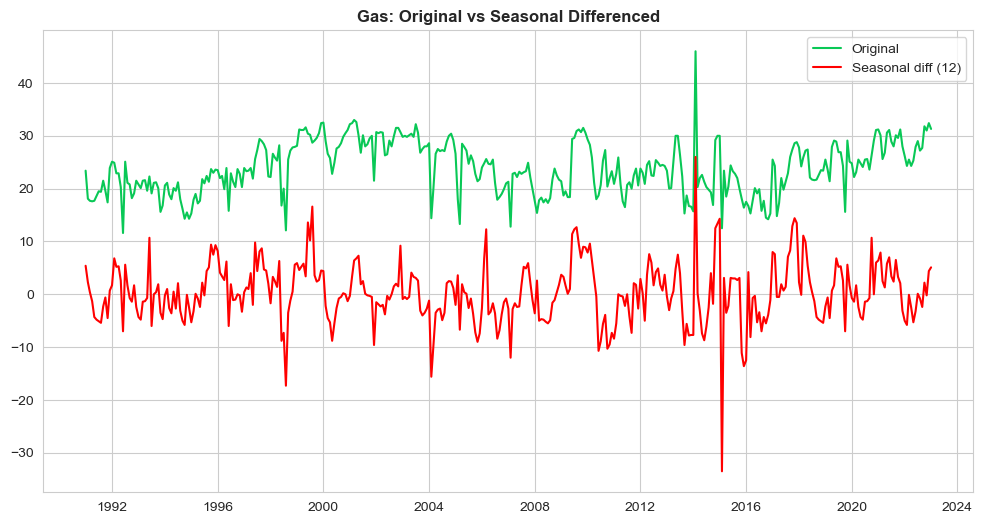

In [18]:
plt.figure(figsize=(12, 6))
plt.plot(energy_df['Gas Consumption (tons)'], label="Original", color='#09C856')
plt.plot(energy_df['Gas_Seasonal_Diff'], label="Seasonal diff (12)", color='#ff0000')
plt.title("Gas: Original vs Seasonal Differenced", fontweight='bold')
plt.legend()
plt.grid(True)
plt.show()


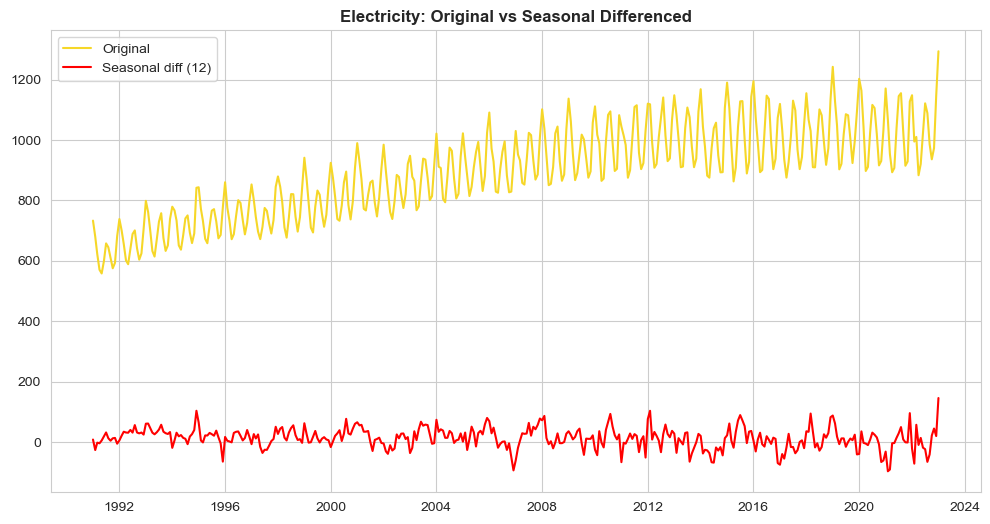

In [19]:
plt.figure(figsize=(12, 6))
plt.plot(energy_df['Electricity Consumption (MWh)'], label="Original", color='#F6D728')
plt.plot(energy_df['Elec_Seasonal_Diff'], label="Seasonal diff (12)", color='#ff0000')
plt.title("Electricity: Original vs Seasonal Differenced", fontweight='bold')
plt.legend()
plt.grid(True)
plt.show()


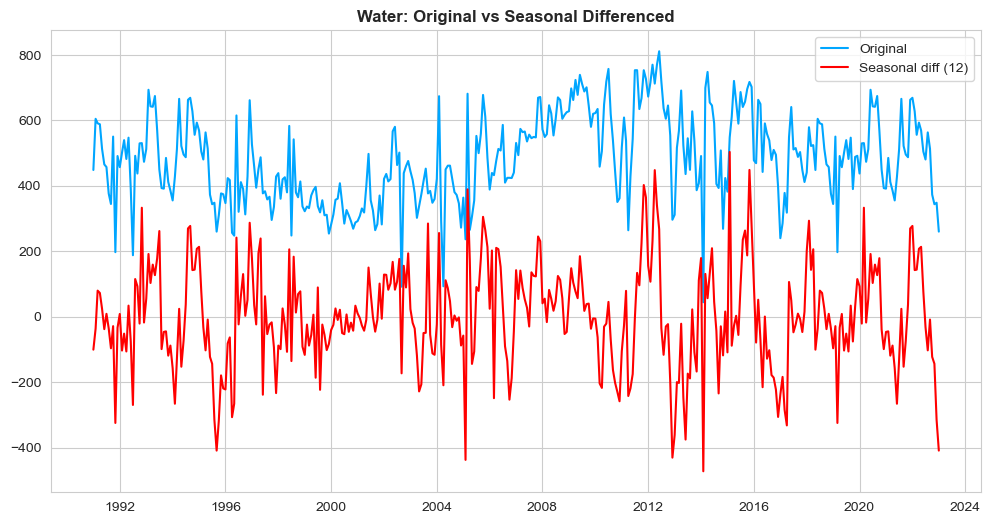

In [20]:
plt.figure(figsize=(12, 6))
plt.plot(energy_df['Water Consumption (tons)'], label="Original", color='#00A6FF')
plt.plot(energy_df['Water_Seasonal_Diff'], label="Seasonal diff (12)", color='#ff0000')
plt.title("Water: Original vs Seasonal Differenced", fontweight='bold')
plt.legend()
plt.grid(True)
plt.show()


### **Key Insights:**
- #### **Gas: Original vs Seasonal Differenced**

  - The original gas series has mild long-term movement + some spikes.

  - The seasonal differenced gas (red) stays mostly around 0, meaning most months don’t change drastically compared to the same month last year.

  - There are a few big spikes in the red line, which suggests anomaly months where gas usage changed a lot year-on-year (might be due to natural occurrences/events).

#### **Takeaway:** Gas has relatively stable year-on-year changes, with a few exceptions (outliers).

- #### **Electricity: Original vs Seasonal Differenced**

  - The original electricity series shows a clear upward trend + strong repeating seasonality.

  - After seasonal differencing, the red line becomes much more centered around 0, meaning the annual seasonal pattern is largely removed.

  - You still see noticeable spikes, showing some months had unusually large increases/decreases compared to the same month last year (these spikes are what the model has to “explain”).

#### **Takeaway:** Electricity’s structure is strongly seasonal, so seasonal differencing helps a lot, but there are still irregular shocks.

- #### **Water: Original vs Seasonal Differenced**

  - The original water series looks more erratic than gas/electricity, with many fluctuations.

  - The seasonal differenced water (red) has much larger swings (big positive and negative spikes), meaning water consumption can change a lot year-on-year.

  - This suggests higher volatility / less predictable behaviour..

#### **Takeaway:** Water has unstable year-on-year changes, so it may be harder to model cleanly with simple ARIMA orders.

## **Step 4.5:** ACF & PACF Plotting 

- **What They Are:**
    - **ACF (Autocorrelation Function):** 
        - Shows correlation between a time series and its **lagged** values
        - Measures how today's value relates to yesterday's and the following and so on so forth.

    - **PACF (Partial Autocorrelation Function):**
        - Shows direct correlation at each lag, removing the effect of intermediate lags
        - Isolates the unique contribution of each specific lag

- **Quick Explanation:**
    - A lag is a time shift backward in a time series, it is the number of time periods that one can step back to to compare with the current value, usually measuered in month.
    - Simple Analogy: How many steps back in time?

- ### **The Main Function:** 
    - These plots help identify the appropriate **ARIMA & SARIMA** parameters **`(p, q)`**:

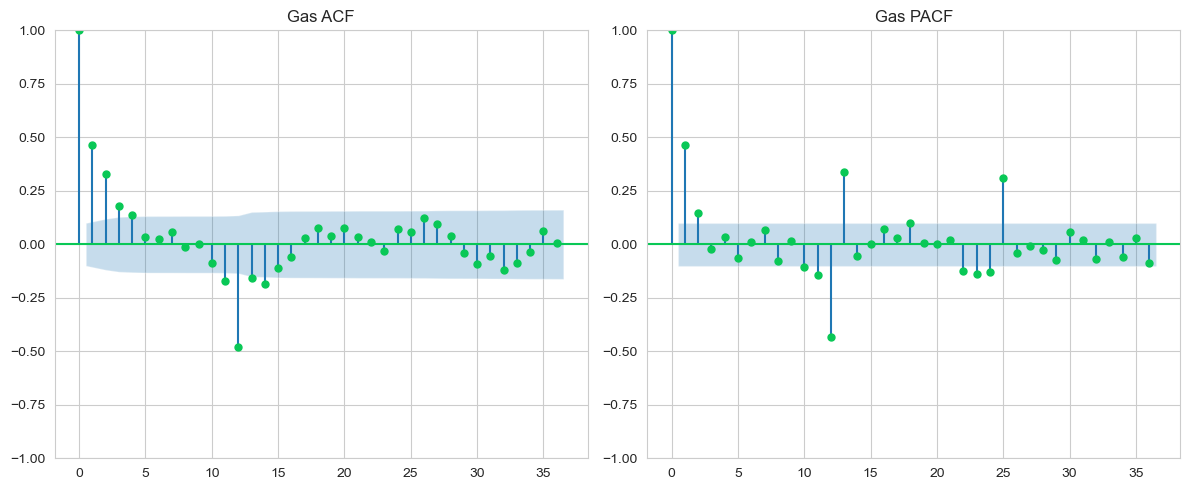

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_acf(energy_df['Gas_Seasonal_Diff'], lags=36, ax=axes[0], color='#09C856')
axes[0].set_title('Gas ACF')
axes[0].grid(True)

plot_pacf(energy_df['Gas_Seasonal_Diff'], lags=36, ax=axes[1], method='ywm', color='#09C856')
axes[1].set_title('Gas PACF')
axes[1].grid(True)

plt.tight_layout()
plt.show()

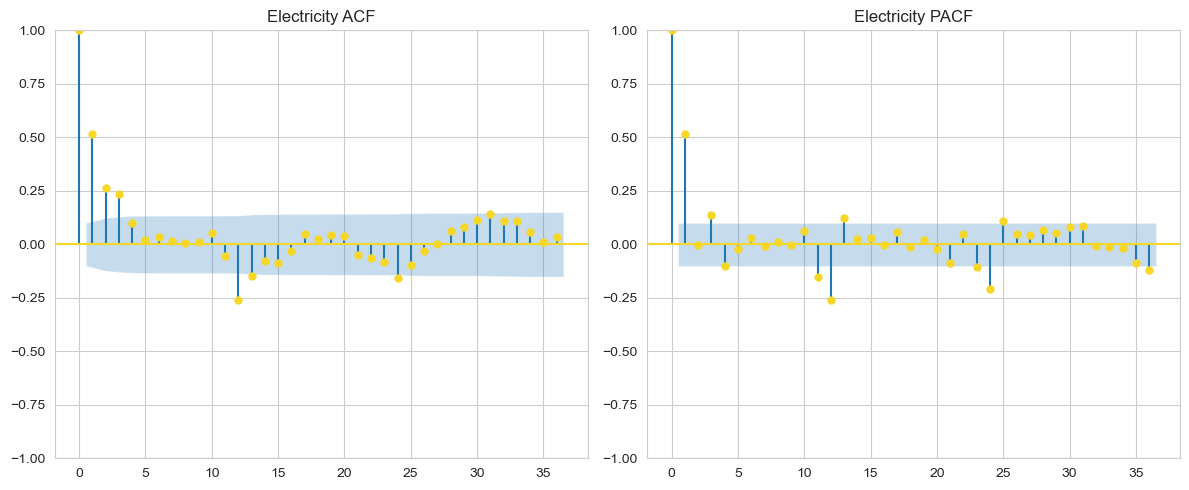

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_acf(energy_df['Elec_Seasonal_Diff'], lags=36, ax=axes[0], color='#F6D728')
axes[0].set_title('Electricity ACF')
axes[0].grid(True)

plot_pacf(energy_df['Elec_Seasonal_Diff'], lags=36, ax=axes[1], method='ywm', color='#F6D728')
axes[1].set_title('Electricity PACF')
axes[1].grid(True)

plt.tight_layout()
plt.show()

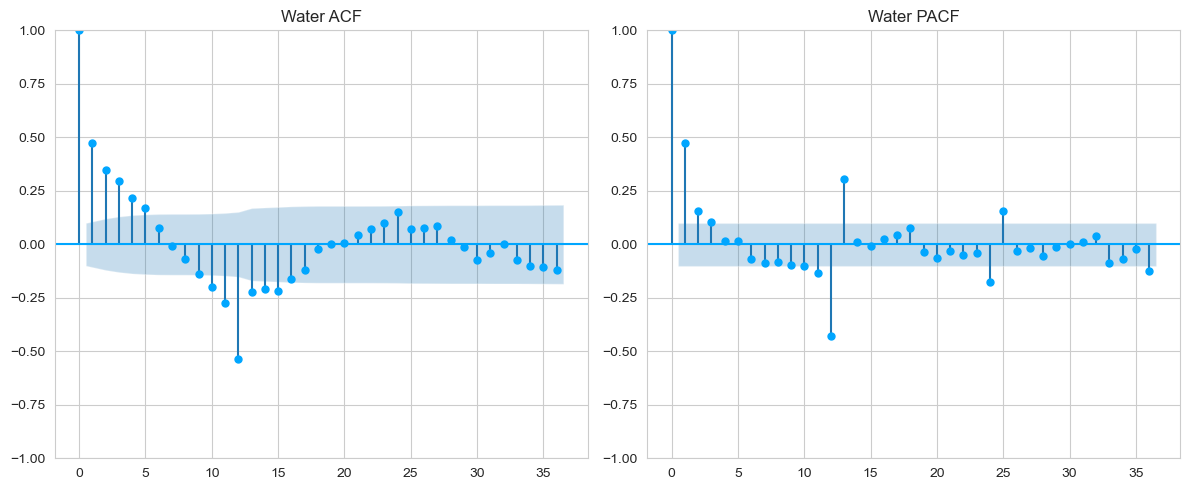

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_acf(energy_df['Water_Seasonal_Diff'], lags=36, ax=axes[0], color='#00A6FF')
axes[0].set_title('Water ACF')
axes[0].grid(True)

plot_pacf(energy_df['Water_Seasonal_Diff'], lags=36, ax=axes[1], method='ywm', color='#00A6FF')
axes[1].set_title('Water PACF')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### **ACF/PACF Analysis for Model Parameter Selection:**



- **Gas:**
    - ACF: strong spikes at lag 1–2, then it weakens - obvious spike around lag 12 → seasonal signal.

    - PACF: strong spike at lag 1 (and maybe a small one at lag 2), then mostly inside the band; also a visible seasonal effect around 12.

- **Electrical:** 
    - ACF: strong at lag 1, decays after → typical “trend / non-stationary-ish” behaviour (or needs differencing).

    - Seasonal pattern shows up around 12 as well (weaker than gas/water, but still there).

    - PACF: big spike at lag 1, then mostly small → suggests low AR order.

- **Water:**
    - ACF: strong at lag 1, decays after → typical “trend / non-stationary-ish” behaviour (or needs differencing).

    - Seasonal pattern shows up around 12 as well (weaker than gas/water, but still there).

    - PACF: big spike at lag 1, then mostly small → suggests low AR order.


- ### **Verdict:**
    - All energy consumptions types should mainly use p=1 and q=1 for ARIMA, with gas and water potentially using q=2 as well.

In [24]:
print("Preprocessing and Feature Engineering Complete!")

print("\nAfter Feature Engineering, here are the present columns in the DataFrame: \n", energy_df.columns)

print(f"\nAnd Here is the shape of the Dataset: {energy_df.shape}")

Preprocessing and Feature Engineering Complete!

After Feature Engineering, here are the present columns in the DataFrame: 
 Index(['Gas Consumption (tons)', 'Electricity Consumption (MWh)',
       'Water Consumption (tons)', 'Gas_SMA_6', 'Gas_SMA_12',
       'Electricity_SMA_6', 'Electricity_SMA_12', 'Water_SMA_6',
       'Water_SMA_12', 'Gas_Seasonal_Diff', 'Elec_Seasonal_Diff',
       'Water_Seasonal_Diff'],
      dtype='object')

And Here is the shape of the Dataset: (385, 12)


- Printing out all the columns in the DataFrame shows the original as well as the newly added columns.
- The shape of the new DataFrame was added, showing that it has a shape of **(385, 12)**, indicating that the DataFrame has 385 rows and 12 columns.

---
## **Step 5:** Model Fitting
In this section, we are going to be fitting 4 models (ARIMA, SARIMA, AUTO-ARIMA and Holt-Winters Exponential Smoothing)

### **Step 5.1:** Train-Val-Test Split
- Split the data into 3 parts, a training set, a validation set and a test set.

In [25]:
n = len(energy_df)
test_size = 60
val_size = 60
train_size = n - test_size - val_size

train = energy_df[:train_size]
val = energy_df[train_size:train_size + val_size]
test = energy_df[train_size + val_size:] 




### **Some Insights:**
- The dataset is split into 3 chronological parts:
    - Training set (all earlier months), Validation set (next 60 months), and Test set (final 60 months).

This keeps the time order intact and prevents data leakage (no future data is used to train the model).

- #### **How the split works:**

    - **`n = len(energy_df)`**
        - Gets the total number of rows (months) in the dataset.

    - **`test_size = 60 and val_size = 60`**
        - Reserves the most recent 60 months for testing and the 60 months before that for validation.

    - **`train_size = n - test_size - val_size`**
        - Whatever is left becomes the training set (385 - 60 - 60 = 265).


- #### **train:**    
    - **`'train = energy_df[:train_size]'`** takes the first part of the dataset (first 265 months).
    - This gives the model the largest historical window to learn trend + seasonality

- #### **val:**
    - **`val = energy_df[train_size:train_size + val_size]`** takes up the next 60 months after the train set.
    - Used to compare models fairly.
    - Tune hyperparameters without touching the test set.
- #### **test:**
    - **`'test = energy_df[train_size + val_size:]'`** takes up the following 60 months after train and val sets a.k.a the last 60 months.
    - It is used only once, at the final, for unbiased model evaluation.


### **Why Split by Month (265-60-60 Train-Val-Test Split) Instead of Using %:**

- Using fixed 60-month blocks makes the evaluation more meaningful because:

    - Forecasting a realistic multi-year horizon (5 years each for validation and testing).

    - Each set contains enough data to capture multiple seasonal cycles (since monthly seasonality is 12, 60 months = 5 full cycles).

- The validation set helps choose the best model/settings without **`“peeking”`** at the test set, so final result is more credible.

- Compared to random splits or only train/test:

    - This method is better for time series, because it respects and preserves temporal order.

    - It reduces the chance of choosing a model that **`“accidentally”`** fits the test period.

In [26]:
print("Total rows:", len(energy_df))

print(f"\nTrain: {len(train)} months (≈{train_size/len(energy_df)*100:.1f}%)")
print("Start:", train.index.min())
print("End:", train.index.max())


print(f"\nValidation: {len(val)} months")
print("Start:", val.index.min())
print("End:", val.index.max())

print(f"\nTest: {len(test)} months")
print("Start:", test.index.min())
print("End:", test.index.max())



Total rows: 385

Train: 265 months (≈68.8%)
Start: 1991-01-01 00:00:00
End: 2013-01-01 00:00:00

Validation: 60 months
Start: 2013-02-01 00:00:00
End: 2018-01-01 00:00:00

Test: 60 months
Start: 2018-02-01 00:00:00
End: 2023-01-01 00:00:00


### Key Insights (Train–Validation–Test Split)

- The training set contains the largest historical portion of the dataset, allowing the models to learn long-term patterns such as **trend, seasonality, and autocorrelation.**

- The validation set **(60 months)** is used for model selection and tuning (e.g., comparing ARIMA vs SARIMAX vs Auto-ARIMA, or SMA-6 vs SMA-12) without touching the final test period.

- The test set **(60 months)** is kept untouched and only used at the end for an unbiased evaluation on the most recent consumption behaviour.

- Instead of a percentage split **(e.g., 70–15–15)**, a fixed-horizon split (Split by months) is chosen because:

    - 60 months = 5 full yearly cycles (since monthly seasonality is 12), which makes validation and test comparisons more reliable.

    - It matches the project goal of forecasting longer-term future consumption, not just a few months ahead.

    - It ensures the evaluation periods are consistent in length, which makes model comparison fairer.


### **Split Train, Validation & Test Datasets Into Respective Energy Sources:**

In [27]:
gas_train, gas_val, gas_test = train['Gas Consumption (tons)'], val['Gas Consumption (tons)'], test['Gas Consumption (tons)']
elec_train, elec_val, elec_test = train['Electricity Consumption (MWh)'], val['Electricity Consumption (MWh)'], test['Electricity Consumption (MWh)']
water_train, water_val, water_test = train['Water Consumption (tons)'], val['Water Consumption (tons)'], test['Water Consumption (tons)']

### **Step 5.2:** Model Fitting - **ARIMA**

In [28]:
gas_arima = ARIMA(gas_train, order=(1, 0, 1)).fit()
elec_arima = ARIMA(elec_train, order=(1, 1, 1)).fit()
water_arima = ARIMA(water_train, order=(1, 0, 1)).fit()



- ARIMA models were first fitted to each consumption series using orders selected based on stationarity tests and autocorrelation patterns. 
- Electricity uses differencing (d=1) due to its non-stationary origin, in order to remove trend effects , while gas and water use d=0 as they are already stationary.
- Taking p and q from the above PACF and ACF Plots.

### **Step 5.3:** Model Fitting - **SARIMA**
- SARIMA is ARIMA + Seasonality.



In [29]:
gas_sarima = SARIMAX(gas_train, 
                      order=(1, 0, 1),
                      seasonal_order=(1, 1, 1, 12)
                      ).fit()
elec_sarima = SARIMAX(elec_train, 
                      order=(1, 1, 1),
                      seasonal_order=(2, 1, 1, 12)
                      ).fit()
water_sarima = SARIMAX(water_train, 
                      order=(1, 0, 1),
                      seasonal_order=(0, 1, 1, 12)
                      ).fit()

# enforce_stationarity=False,
#                       enforce_invertibility=False
# enforce_stationarity=False,
#                       enforce_invertibility=False
# enforce_stationarity=False,
#                       enforce_invertibility=False
# disp=False
# disp=False
# disp=False


- SARIMAX models are implemented separately for electricity, gas, and water to capture both trend and seasonal dynamics in each energy series.

- SARIMAX extends ARIMA by adding seasonal awareness, allowing the model to learn repeating consumption patterns such as yearly or monthly cycles that are common in energy usage.

- ### **Parameters used:**
    - **`'seasonal_order'`** is taking the orginal order with the addition of the number of periods per cycle, in this case, its 12, which represents a 12-month seasonal cycle.
        - Taking the trend every 12-months/year.
        - Take D=1 for electricity and water consumptions

### **Step 5.4:** Model Fitting - **Auto-ARIMA**

In [30]:
gas_aarima = auto_arima(gas_train,
                         seasonal=True,
                         m=12,
                         stepwise=True,
                         trace=True,
                         suppress_warnings=True,
                         error_action="ignore")

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=1340.281, Time=1.34 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=1374.514, Time=0.04 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=1361.085, Time=0.14 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=1353.755, Time=0.13 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=1372.514, Time=0.03 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=1339.642, Time=0.66 sec
 ARIMA(2,1,2)(0,0,0)[12] intercept   : AIC=1338.276, Time=0.32 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=1339.514, Time=0.76 sec
 ARIMA(1,1,2)(0,0,0)[12] intercept   : AIC=1336.343, Time=0.20 sec
 ARIMA(1,1,2)(1,0,0)[12] intercept   : AIC=1337.588, Time=0.38 sec
 ARIMA(1,1,2)(0,0,1)[12] intercept   : AIC=1337.716, Time=0.48 sec
 ARIMA(1,1,2)(1,0,1)[12] intercept   : AIC=1338.344, Time=0.95 sec
 ARIMA(0,1,2)(0,0,0)[12] intercept   : AIC=1345.607, Time=0.09 sec
 ARIMA(1,1,1)(0,0,0)[12] intercept   : AIC=1334.696, Time=0.10 sec
 ARIMA(1,1,1)(1,0,0

In [31]:
elec_aarima = auto_arima(elec_train,
                         seasonal=True,
                         m=12,
                         stepwise=True,
                         trace=True,
                         suppress_warnings=True,
                         error_action="ignore")

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=inf, Time=1.63 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=2989.059, Time=0.03 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=inf, Time=0.46 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=2763.550, Time=0.39 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=2987.196, Time=0.02 sec
 ARIMA(0,1,1)(0,0,0)[12] intercept   : AIC=2911.743, Time=0.09 sec
 ARIMA(0,1,1)(1,0,1)[12] intercept   : AIC=2448.045, Time=0.94 sec
 ARIMA(0,1,1)(1,0,0)[12] intercept   : AIC=2531.362, Time=0.38 sec
 ARIMA(0,1,1)(2,0,1)[12] intercept   : AIC=2450.038, Time=2.30 sec
 ARIMA(0,1,1)(1,0,2)[12] intercept   : AIC=2450.575, Time=3.16 sec
 ARIMA(0,1,1)(0,0,2)[12] intercept   : AIC=2711.266, Time=0.98 sec
 ARIMA(0,1,1)(2,0,0)[12] intercept   : AIC=2494.955, Time=1.26 sec
 ARIMA(0,1,1)(2,0,2)[12] intercept   : AIC=inf, Time=2.93 sec
 ARIMA(0,1,0)(1,0,1)[12] intercept   : AIC=2473.318, Time=0.74 sec
 ARIMA(1,1,1)(1,0,1)[12] intercept

In [32]:
water_aarima = auto_arima(water_train,
                         seasonal=True,
                         m=12,
                         stepwise=True,
                         trace=True,
                         suppress_warnings=True,
                         error_action="ignore")

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[12] intercept   : AIC=3184.222, Time=1.29 sec
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=3242.665, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=3216.170, Time=0.11 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=3195.640, Time=0.38 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=3240.671, Time=0.02 sec
 ARIMA(2,1,2)(0,0,1)[12] intercept   : AIC=3186.275, Time=1.16 sec
 ARIMA(2,1,2)(1,0,0)[12] intercept   : AIC=3186.258, Time=1.17 sec
 ARIMA(2,1,2)(2,0,1)[12] intercept   : AIC=3182.494, Time=3.08 sec
 ARIMA(2,1,2)(2,0,0)[12] intercept   : AIC=3180.348, Time=2.60 sec
 ARIMA(1,1,2)(2,0,0)[12] intercept   : AIC=3178.860, Time=1.70 sec
 ARIMA(1,1,2)(1,0,0)[12] intercept   : AIC=3184.728, Time=0.70 sec
 ARIMA(1,1,2)(2,0,1)[12] intercept   : AIC=3180.749, Time=2.46 sec
 ARIMA(1,1,2)(1,0,1)[12] intercept   : AIC=3184.519, Time=0.86 sec
 ARIMA(0,1,2)(2,0,0)[12] intercept   : AIC=3182.219, Time=0.93 sec
 ARIMA(1,1,1)(2,0,0

- Auto-ARIMA is applied separately to electricity, gas, and water using the training set only to avoid data leakage.

- Auto-ARIMA automatically searches through multiple ARIMA configurations and selects the best-performing model, reducing manual trial-and-error and ensuring a more objective choice of parameters.

- ### **Parameters Used:**
    - **`'seasonal=True'`** enables SARIMA-style seasonal search.

    - **`'m=12'`** represents a 12 month seasonal cycle.

    - **`'stepwise=True'`** enables faster and smarter parameter search.
    
    - **`'trace=True'`** shows what models are being tested.

    - **`'suppress_warnings=True'`** hides harmless warnings.

    - **`'error_action="ignore"'`** skips failed model configs.


- ### **Results:**
    - Auto-ARIMA selected  ARIMA(1,1,1)(0,0,0)[12] as the best ARIMA model for gas consumption, indicating differencing is useful but seasonal terms are not strongly needed.
    
    - Auto-ARIMA selected ARIMA(1,1,2)(1,0,1)[12] as the best ARIMA model for electricity consumption, suggesting the series requires differencing (`d=1`) and contains yearly seasonal behaviour (`m=12`).
    

    - Auto-ARIMA selected ARIMA(1,1,1)(2,0,0)[12] as the best ARIMA model for water consumption, indicating differencing is useful and some seasonal structure exists (seasonal AR terms).


- **Note:**
    - Despite ADF test shows that both gas and water consumption are stationary, d=1 is included in the order of auto-ARIMA as it optimises AIC scores and sometimes picks differencing if it helps improve the overall AIC score and forecastin performance.

Overall, the selected models provide a data-driven benchmark to compare against ARIMA & SARIMAX settings using validation MAE/RMSE as well as AIC & BIC.

### **Step 5.5:** Holt Winter's Exponential Smoothing

In [33]:
gas_hw = ExponentialSmoothing(
    gas_train,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

gas_hw_forecast = gas_hw.forecast(steps=len(val))

elec_hw = ExponentialSmoothing(
    elec_train,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

elec_hw_forecast = elec_hw.forecast(steps=len(val))



water_hw = ExponentialSmoothing(
    water_train,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

water_hw_forecast = water_hw.forecast(steps=len(val))

water_hw_mae = mean_absolute_error(water_val, water_hw_forecast)
water_hw_rmse = root_mean_squared_error(water_val, water_hw_forecast)



- An additive Holt-Winters model was applied to Gas, Electricity, and Water consumption.

- Additive trend and additive seasonality were selected, assuming seasonal fluctuations remain relatively constant over time.

- A seasonal period of 12 was used to capture yearly seasonality in monthly data.


---
## **Step 6:** Model Evaluation
In this section, we are going to evaluate the performance of each model by comparing their Akaike Information Criterion (AIC) & Bayesian Information Criterion (BIC) scores, and error management (MAE, RMSE).

Chose 1 model out of the 3 that yields the best results and that model will be our finalised model.

### **Step 6.1:** Evaluation Using Root Mean Squared Error **(RMSE)** & Mean Absolute Error **(MAE)** 


#### **Step 6.1.1:** ARIMA 

In [34]:

gas_arima_forecast = gas_arima.forecast(steps=len(val))

gas_arima_mae = mean_absolute_error(gas_val, gas_arima_forecast)
gas_arima_rmse = root_mean_squared_error(gas_val, gas_arima_forecast)

print("\nGas Consumption ARIMA MAE:", round(gas_arima_mae, 2), "\nGas Consumption ARIMA RMSE:", round(gas_arima_rmse, 2))

elec_arima_forecast = elec_arima.forecast(steps=len(val))

elec_arima_mae = mean_absolute_error(elec_val, elec_arima_forecast)
elec_arima_rmse = root_mean_squared_error(elec_val, elec_arima_forecast)

print("Electricity Consumption ARIMA MAE:", round(elec_arima_mae, 2), "\nElectricity Consumption ARIMA RMSE:", round(elec_arima_rmse, 2))

water_arima_forecast = water_arima.forecast(steps=len(val))

water_arima_mae = mean_absolute_error(water_val, water_arima_forecast)
water_arima_rmse = root_mean_squared_error(water_val, water_arima_forecast)

print("\nWater Consumption ARIMA MAE:", round(water_arima_mae, 2), "\nWater Consumption ARIMA RMSE:", round(water_arima_rmse, 2))





Gas Consumption ARIMA MAE: 4.97 
Gas Consumption ARIMA RMSE: 6.06
Electricity Consumption ARIMA MAE: 149.45 
Electricity Consumption ARIMA RMSE: 174.65

Water Consumption ARIMA MAE: 121.49 
Water Consumption ARIMA RMSE: 150.41


#### **Step 6.1.2:** SARIMA

In [35]:
gas_sarima_forecast = gas_sarima.forecast(steps=len(val))

gas_sarima_mae = mean_absolute_error(gas_val, gas_sarima_forecast)
gas_sarima_rmse = root_mean_squared_error(gas_val, gas_sarima_forecast)

print("\nGas Consumption SARIMA MAE:", round(gas_sarima_mae, 2), "\nGas Consumption SARIMA RMSE:", round(gas_sarima_rmse, 2))


elec_sarima_forecast = elec_sarima.forecast(steps=len(val))

elec_sarima_mae = mean_absolute_error(elec_val, elec_sarima_forecast)
elec_sarima_rmse = root_mean_squared_error(elec_val, elec_sarima_forecast)

print("Electricity Consumption SARIMA MAE:", round(elec_sarima_mae, 2), "\nElectricity Consumption SARIMA RMSE:", round(elec_sarima_rmse, 2))



water_sarima_forecast = water_sarima.forecast(steps=len(val))

water_sarima_mae = mean_absolute_error(water_val, water_sarima_forecast)
water_sarima_rmse = root_mean_squared_error(water_val, water_sarima_forecast)

print("\nWater Consumption SARIMA MAE:", round(water_sarima_mae, 2), "\nWater Consumption SARIMA RMSE:", round(water_sarima_rmse, 2))





Gas Consumption SARIMA MAE: 4.91 
Gas Consumption SARIMA RMSE: 6.13
Electricity Consumption SARIMA MAE: 59.18 
Electricity Consumption SARIMA RMSE: 68.48

Water Consumption SARIMA MAE: 104.55 
Water Consumption SARIMA RMSE: 138.12


#### **Step 6.1.3:** Auto-ARIMA

In [36]:
gas_aarima_forecast = gas_aarima.predict(n_periods=len(val))

gas_aarima_mae = mean_absolute_error(gas_val, gas_aarima_forecast)
gas_aarima_rmse = root_mean_squared_error(gas_val, gas_aarima_forecast)

print("\nGas Consumption Auto-ARIMA MAE:", round(gas_aarima_mae, 2), "\nGas Consumption Auto-ARIMA RMSE:", round(gas_aarima_rmse, 2))

elec_aarima_forecast = elec_aarima.predict(n_periods=len(val))

elec_aarima_mae = mean_absolute_error(elec_val, elec_aarima_forecast)
elec_aarima_rmse = root_mean_squared_error(elec_val, elec_aarima_forecast)

print("Electricity Consumption Auto-ARIMA MAE:", round(elec_aarima_mae, 2), "\nElectricity Consumption Auto-ARIMA RMSE:", round(elec_aarima_rmse, 2))




water_aarima_forecast = water_aarima.predict(n_periods=len(val))

water_aarima_mae = mean_absolute_error(water_val, water_aarima_forecast)
water_aarima_rmse = root_mean_squared_error(water_val, water_aarima_forecast)

print("\nWater Consumption Auto-ARIMA MAE:", round(water_aarima_mae, 2), "\nWater Consumption Auto-ARIMA RMSE:", round(water_aarima_rmse, 2))


Gas Consumption Auto-ARIMA MAE: 4.77 
Gas Consumption Auto-ARIMA RMSE: 5.91
Electricity Consumption Auto-ARIMA MAE: 57.39 
Electricity Consumption Auto-ARIMA RMSE: 67.19

Water Consumption Auto-ARIMA MAE: 116.84 
Water Consumption Auto-ARIMA RMSE: 150.42


#### **Step 6.1.4:** Holt Winters

In [37]:
gas_hw_mae = mean_absolute_error(gas_val, gas_hw_forecast)
gas_hw_rmse = root_mean_squared_error(gas_val, gas_hw_forecast)

print("Gas HW MAE:", round(gas_hw_mae, 2))
print("Gas HW RMSE:", round(gas_hw_rmse, 2))

elec_hw_mae = mean_absolute_error(elec_val, elec_hw_forecast)
elec_hw_rmse = root_mean_squared_error(elec_val, elec_hw_forecast)

print("\nElectricity HW MAE:", round(elec_hw_mae, 2))
print("Electricity HW RMSE:", round(elec_hw_rmse, 2))

water_hw_mae = mean_absolute_error(water_val, water_hw_forecast)
water_hw_rmse = root_mean_squared_error(water_val, water_hw_forecast)

print("\nWater HW MAE:", round(water_hw_mae, 2))
print("Water HW RMSE:", round(water_hw_rmse, 2))

Gas HW MAE: 4.76
Gas HW RMSE: 6.02

Electricity HW MAE: 62.99
Electricity HW RMSE: 73.57

Water HW MAE: 138.98
Water HW RMSE: 170.39


In [38]:
all_metrics_results = pd.DataFrame({
    "Energy Types": ["Gas", "Electricity", "Water"],

    # ---------- ARIMA ----------
    "ARIMA_MAE":  [gas_arima_mae,  elec_arima_mae,  water_arima_mae],
    "ARIMA_RMSE": [gas_arima_rmse, elec_arima_rmse, water_arima_rmse],
    "ARIMA_AIC":  [gas_arima.aic,  elec_arima.aic,  water_arima.aic],
    "ARIMA_BIC":  [gas_arima.bic,  elec_arima.bic,  water_arima.bic],

    # ---------- SARIMAX ----------
    "SARIMAX_MAE":  [gas_sarima_mae,  elec_sarima_mae,  water_sarima_mae],
    "SARIMAX_RMSE": [gas_sarima_rmse, elec_sarima_rmse, water_sarima_rmse],
    "SARIMAX_AIC":  [gas_sarima.aic,  elec_sarima.aic,  water_sarima.aic],
    "SARIMAX_BIC":  [gas_sarima.bic,  elec_sarima.bic,  water_sarima.bic],

    # ---------- AUTO-ARIMA ----------
    "AUTO-ARIMA_MAE":  [gas_aarima_mae,  elec_aarima_mae,  water_aarima_mae],
    "AUTO-ARIMA_RMSE": [gas_aarima_rmse, elec_aarima_rmse, water_aarima_rmse],
    "AUTO-ARIMA_AIC":  [gas_aarima.aic(),  elec_aarima.aic(),  water_aarima.aic()],
    "AUTO-ARIMA_BIC":  [gas_aarima.bic(),  elec_aarima.bic(),  water_aarima.bic()],

    # ---------- HOLT-WINTERS ----------
    "HW_MAE":  [gas_hw_mae,  elec_hw_mae,  water_hw_mae],
    "HW_RMSE": [gas_hw_rmse, elec_hw_rmse, water_hw_rmse],
    "HW_AIC":  [gas_hw.aic,  elec_hw.aic,  water_hw.aic],
    "HW_BIC":  [gas_hw.bic,  elec_hw.bic,  water_hw.bic],
}).round(2)

all_metrics_results


,Energy Types,ARIMA_MAE,ARIMA_RMSE,ARIMA_AIC,ARIMA_BIC,SARIMAX_MAE,SARIMAX_RMSE,SARIMAX_AIC,SARIMAX_BIC,AUTO-ARIMA_MAE,AUTO-ARIMA_RMSE,AUTO-ARIMA_AIC,AUTO-ARIMA_BIC,HW_MAE,HW_RMSE,HW_AIC,HW_BIC
0,Gas,4.97,6.06,1344.54,1358.86,4.91,6.13,1319.37,1337.03,4.77,5.91,1332.79,1343.52,4.76,6.02,617.70,674.97
1,Electricity,149.45,174.65,2911.46,2922.19,59.18,68.48,2269.49,2290.66,57.39,67.19,2405.69,2427.15,62.99,73.57,1675.61,1732.89
2,Water,121.49,150.41,3196.43,3210.75,104.55,138.12,3079.60,3093.74,116.84,150.42,3175.63,3193.51,138.98,170.39,2463.93,2521.21


### **Justification for Using RMSE & MAE:**

RMSE and MAE are used jointly to evaluate forecasting performance because they capture complementary error behaviours, with RMSE beign the main evaluation metric.

- But Why RMSE as main evaluation metric:
    - RMSE squares the error before averaging, thereby penalising large forecasting errors more heavily, which matters for planning/forecasting where big errors are costly, especially for electricity consumption, where large deviaions can lead to operational and planning (real-world) risks

- MAE as Supporting Evaluation Metric:
    - MAE measures the average absolute deviation between predicted and actual values, providing an intuitive and robust estimate of typical forecast error in the same unit as the data.

- However, using both metrics ensures a balanced assessment: 
    - MAE reflects general prediction accuracy, while RMSE highlights sensitivity to large forecast misses. This dual-metric approach prevents misleading conclusions that may arise from relying on a single error measure.

### **Key Insights (Model Evaluation – Validation Set)**

- Model performance is first evaluated using MAE and RMSE on the validation set to assess real-world forecasting accuracy.
- For electricity, the model with the lower RMSE is prioritised due to the strong upward trend and higher sensitivity to large errors.
- For gas and water, MAE is considered alongside RMSE to balance robustness against volatility and outliers.

- AIC and BIC are then used as secondary criteria to assess model complexity and goodness of fit.


- The final forecasting model for each energy series is selected based on a combination of:
  
  (i) RMSE,  
  
  (ii) MAE

  (iii) reasonable AIC/BIC values indicating stable model complexity.

## **Final Model For Each Energy Type:**
- **Gas: Holt Winters**

- **Electricity: SARIMA**

- **Water: SARIMA**

### **Justification:**

- #### Gas:
    - Based on the judging criteria, Holt-Winters produced the lowest MAE score, of 4.76, beating AUTO-ARIMA by 0.01 and SARIMA by 0.14. 
    - It came in 2nd in RMSE, behind AUTO-ARIMA, but the difference between them is very small.
    - It had the lowest AIC and BIC Score as compared to the other ARIMA models.
    - Seasonality is not as strong as Electricity hence chose Holt-Winters.

- #### Electricity:
    - Electricity exhibited strong seasonal behaviour with clear annual patterns, making SARIMAX more suitable as it captures both non-seasonal and seasonal dynamics effectively.
    - AUTO-ARIMA has a lower error score, but the difference is very small so I chose SARIMA instead due to the obvious seasonality.

- ##### Water:
    - Despite not having as high seasonality as electricity, SARIMA still gave the lowest RMSE and MAE score hence I decided on using SARIMA as the model for water, as there might also be seasonality in the future as we do not know how people of the future might consume water.


## **Step 6.2:** Visualize Forecasting **BEFORE** Hyperparameter Tuning:
- Before we tune the hyperparameters of the respective models, let's first plot their graphs to analyse how well each model forecasts the next 60 months.
- However, we are forecasting on the validation set first and not the test set as we do not want any data leakages.

### Gas Forecast

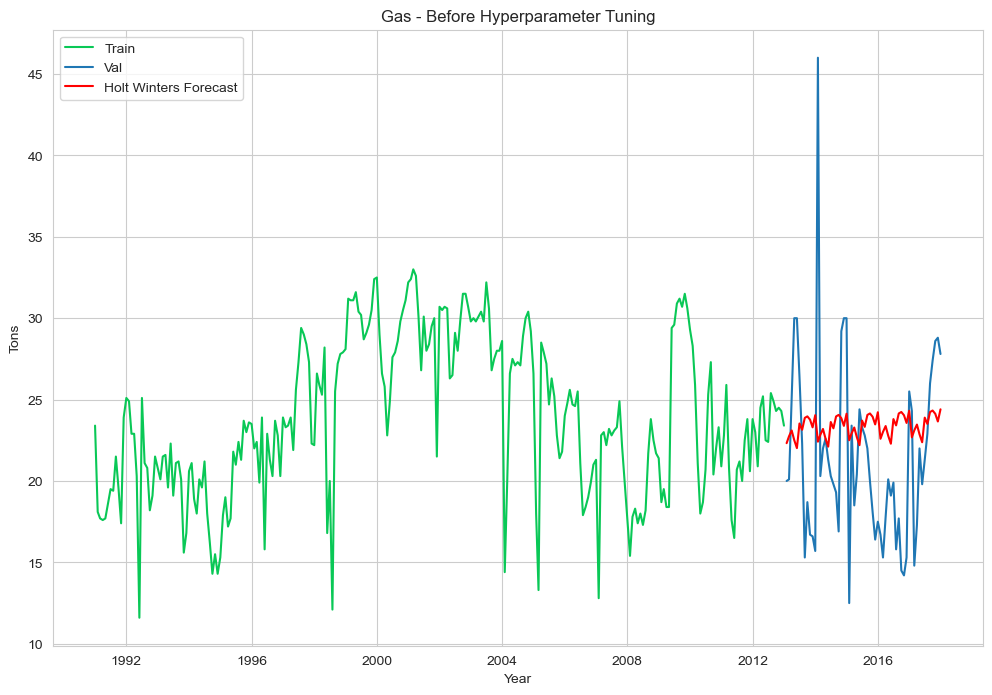

In [39]:
plt.figure(figsize=(12, 8))
plt.plot(gas_train, label="Train", color='#09C856')
plt.plot(gas_val, label='Val')
plt.plot(gas_hw_forecast, label="Holt Winters Forecast", color='#ff0000')
plt.title("Gas - Before Hyperparameter Tuning")
plt.xlabel("Year")
plt.ylabel("Tons")
plt.legend()

plt.show()


### Electricity Forecast:

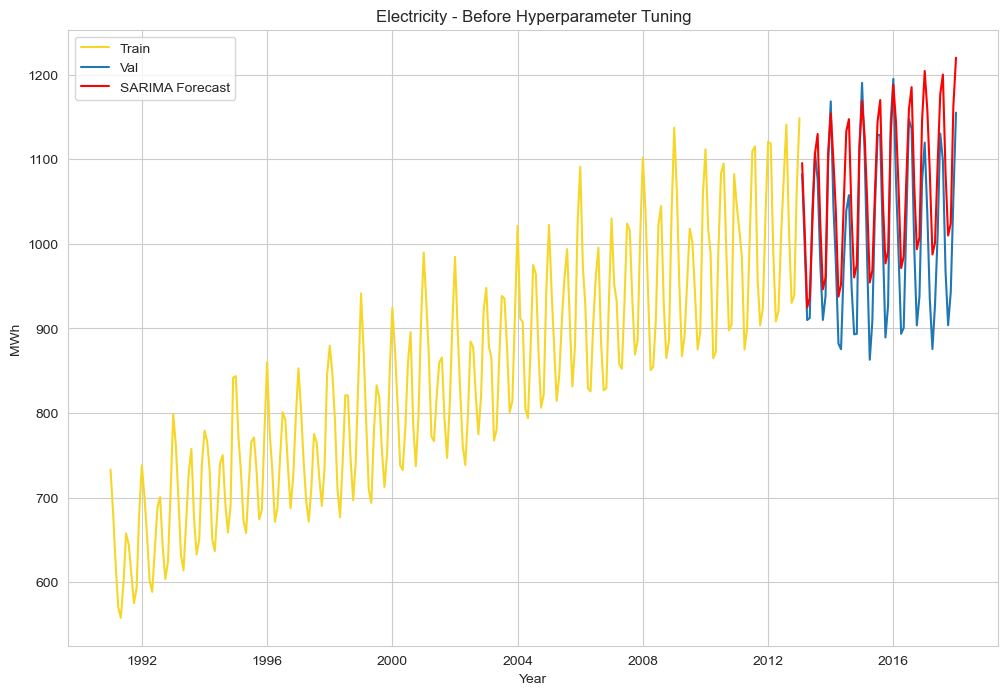

In [40]:
plt.figure(figsize=(12, 8))
plt.plot(elec_train, label="Train", color='#F6D728')
plt.plot(elec_val, label='Val')
plt.plot(elec_sarima_forecast, label="SARIMA Forecast", color='#ff0000')
plt.title("Electricity - Before Hyperparameter Tuning")
plt.xlabel("Year")
plt.ylabel("MWh")
plt.legend()
plt.show()


### Water Forecasting

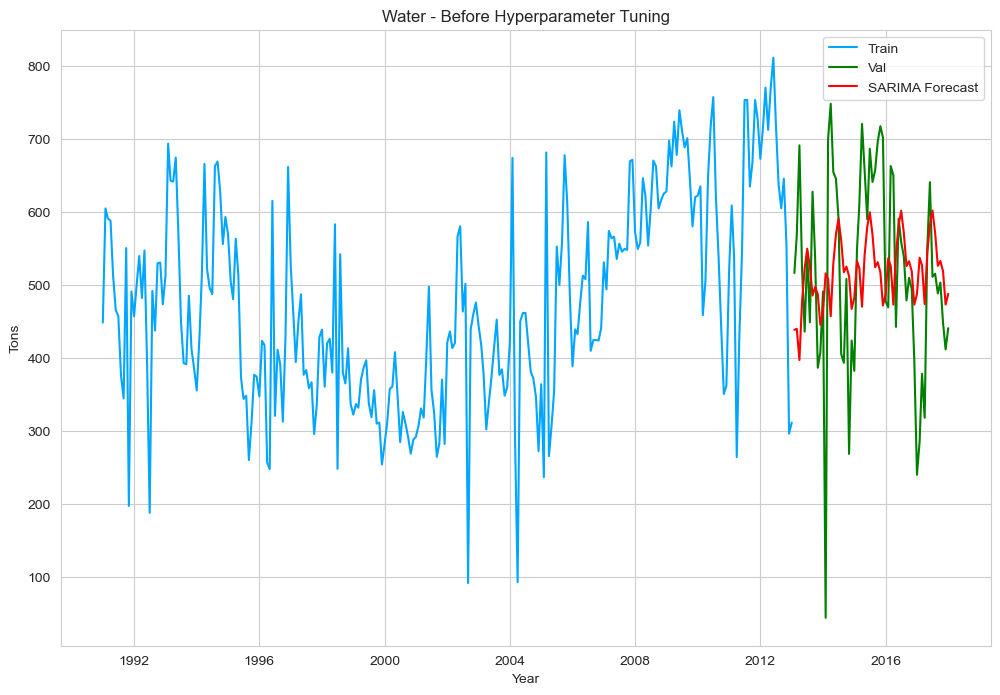

In [41]:
plt.figure(figsize=(12, 8))
plt.plot(water_train, label="Train", color='#00A6FF')
plt.plot(water_val, label='Val', color='green')
plt.plot(water_sarima_forecast, label="SARIMA Forecast", color='#ff0000')
plt.title("Water - Before Hyperparameter Tuning")
plt.xlabel("Year")
plt.ylabel("Tons")
plt.legend()
plt.show()


### **Some Insights:**
*Side note: Validation forecast is to simulate the performance of the model on unseen future data. This is valid because the validation set consists of time periods that were not used during model training, giving an unbiased performance.


- **Gas:**
    - Holt-Winters model captures the general level of gas consumption but underestimates sudden spikes and sharp fluctuations.

    - Forecasted values appear smoother than the actual validation data, indicating that the model may not fully capture irregular volatility.

    - Seasonal effects are partially reflected, but extreme values are not well tracked.

    - This suggests that further tuning of trend/seasonal parameters may improve responsiveness to demand variations.


- **Electricity:**
    - The SARIMA model successfully captures the strong annual seasonal pattern.

    - Forecasted peaks and troughs align closely with the validation data, showing good seasonal modelling.

    - However, slight overestimation is observed in later validation periods.

    - The amplitude of the forecast appears slightly exaggerated, indicating room for hyperparameter optimisation.

- **Water:**
    - The baseline SARIMA model struggles to fully capture irregular fluctuations in water consumption.

    - Although some seasonal behaviour is reflected, the forecast appears overly smooth compared to the validation data.

    - Sharp drops and spikes in the validation period are not well captured.

    - This suggests that the current parameter settings may not adequately model the underlying noise and mild seasonality.

These visuals plotted above show the estimation of the forecast, as you can see, it can definitely be improved. Hence, in the next section, we are going to do just that.

---
## **Step 7:** Model Improvement **(Hyperparameter Tuning)**

Implement hyperparameter tuning to the selected model in order to obtain the best parameters that can achieve the most optimal results and predictions.
- Why are hyperparameters tuned:

  - Hyperparameters are tuned because there are more optimal settings that allows the model to achieve even better results than its default settings.
  - It also makes the model more accurate and reduces overfitting.
  - Hyperparameter tuning is able to find that sweet spot between having complex data (overfitting) & too little data (underfitting). 


⚙️ Tuning Method Used: Grid Search with **TimeSeriesSplit**

For this project, hyperparameter tuning is performed using a grid search approach combined with TimeSeriesSplit cross-validation.

- ### **Process:**

    - A range of possible hyperparameter combinations is defined:

        -  #### **For SARIMA:**
            - Non-seasonal order (p, d, q)

            - Seasonal order (P, D, Q, 12)

        - #### **For Holt-Winters:**
            - Trend type (additive / none)

            - Seasonal type (additive / multiplicative)

            - Damped trend option
            

- For each parameter combination:

    - The model is trained on progressively expanding training folds using TimeSeriesSplit.

    - Forecasts are generated for each validation fold.

    - The forecasting error (RMSE and MAE) is computed for each fold.

- The average RMSE across all folds is calculated.

- The parameter combination with the lowest average RMSE is selected as the optimal configuration.

## **Step 7.1:** Tuning Hyperparameters

### **Step 7.1.1:** Hyperparameter Tuning for Gas

In [42]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y = gas_train  # your gas training series

m = 12  # monthly -> yearly seasonality
tscv = TimeSeriesSplit(n_splits=3)

# keep grid small so it doesn't take forever
trend_list = ["add", None]
seasonal_list = ["add", None]

best = {"cv_rmse": float("inf"), "trend": None, "seasonal": None}

for trend in trend_list:
    for seasonal in seasonal_list:

        fold_rmses = []
        try:
            for tr_idx, va_idx in tscv.split(y):
                y_tr = y.iloc[tr_idx]
                y_va = y.iloc[va_idx]

                model = ExponentialSmoothing(
                    y_tr,
                    trend=trend,
                    seasonal=seasonal,
                    seasonal_periods=m if seasonal is not None else None
                ).fit(optimized=True)

                pred = model.forecast(len(y_va))
                fold_rmses.append(rmse(y_va, pred))

            avg_rmse = float(np.mean(fold_rmses))

            if avg_rmse < best["cv_rmse"]:
                best.update({"cv_rmse": avg_rmse, "trend": trend, "seasonal": seasonal})

        except Exception:
            continue

print("✅ Best GAS Holt-Winters (TimeSeriesSplit CV)")
print("CV RMSE:", round(best["cv_rmse"], 4))
print("trend:", best["trend"])
print("seasonal:", best["seasonal"])

best_gas_hw = ExponentialSmoothing(
    gas_train,
    trend=best["trend"],
    seasonal=best["seasonal"],
    seasonal_periods=12 if best["seasonal"] is not None else None
).fit(optimized=True)

gas_val_pred = best_gas_hw.forecast(len(gas_val))

gas_val_mae = mean_absolute_error(gas_val, gas_val_pred)
gas_val_rmse = root_mean_squared_error(gas_val, gas_val_pred)

print("Tuned Gas Holt-Winters - Validation MAE:", round(gas_val_mae, 3))
print("Tuned Gas Holt-Winters - Validation RMSE:", round(gas_val_rmse, 3))
print("AIC:", round(best_gas_hw.aic, 2), "| BIC:", round(best_gas_hw.bic, 2))


✅ Best GAS Holt-Winters (TimeSeriesSplit CV)
CV RMSE: 5.4634
trend: None
seasonal: None
Tuned Gas Holt-Winters - Validation MAE: 4.96
Tuned Gas Holt-Winters - Validation RMSE: 6.056
AIC: 603.15 | BIC: 610.31


### **Step 7.1.2:** Hyperparameter Tuning for Electricity

In [43]:
def rmse(y_true, y_pred):
    return (root_mean_squared_error(y_true, y_pred))

# ====== Electricity series (train only) ======
y = elec_train  # you already defined elec_train from train split

# ====== Based on your stationarity + seasonality findings ======
d = 1          # Electricity non-stationary -> needs differencing
D_list = [0, 1] # Seasonal differencing to remove yearly cycle (monthly data)
m = 12         # monthly seasonality

# ====== Small grid (ACF/PACF-guided, fast) ======
p_list = [0, 1, 2]
q_list = [0, 1, 2]
P_list = [0, 1]
Q_list = [0, 1]

# 3 folds keeps runtime reasonable
tscv = TimeSeriesSplit(n_splits=3)

best = {"cv_rmse": float("inf"), "order": None, "seasonal_order": None}

for p, q, P, D, Q in itertools.product(p_list, q_list, P_list, D_list, Q_list):
    order = (p, d, q)
    seasonal_order = (P, D, Q, m)

    fold_rmses = []
    try:
        for train_idx, val_idx in tscv.split(y):
            y_tr = y.iloc[train_idx]
            y_va = y.iloc[val_idx]

            model = SARIMAX(
                y_tr,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False)

            pred = model.forecast(steps=len(y_va))
            fold_rmses.append(rmse(y_va, pred))

        avg_rmse = float(np.mean(fold_rmses))

        if avg_rmse < best["cv_rmse"]:
            best.update({
                "cv_rmse": avg_rmse,
                "order": order,
                "seasonal_order": seasonal_order
            })

    except:
        continue

print("✅ Best ELECTRICITY (TimeSeriesSplit CV)")
print("CV RMSE:", round(best["cv_rmse"], 4))
print("order:", best["order"])
print("seasonal_order:", best["seasonal_order"])

best_elec_sarima = SARIMAX(
    elec_train,
    order=best["order"],
    seasonal_order=best["seasonal_order"],
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

elec_val_pred = best_elec_sarima.forecast(steps=len(elec_val))

elec_val_mae = mean_absolute_error(elec_val, elec_val_pred)
elec_val_rmse = rmse(elec_val, elec_val_pred)

print("\nTuned Electricity SARIMA - Validation MAE:", round(elec_val_mae, 3))
print("Tuned Electricity SARIMA - Validation RMSE:", round(elec_val_rmse, 3))
print("AIC:", round(best_elec_sarima.aic, 2), "| BIC:", round(best_elec_sarima.bic, 2)) 




✅ Best ELECTRICITY (TimeSeriesSplit CV)
CV RMSE: 30.3148
order: (2, 1, 2)
seasonal_order: (1, 1, 1, 12)

Tuned Electricity SARIMA - Validation MAE: 63.776
Tuned Electricity SARIMA - Validation RMSE: 74.068
AIC: 2145.13 | BIC: 2169.4


### **Step 7.1.3:** Hyperparameter Tuning For Water

In [44]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

# ====== WATER series (train only) ======
y = water_train

# ====== Based on your findings ======
d_list = [0, 1]         # water stationary from ADF -> no non-seasonal differencing
D_list = [0, 1]          # seasonal differencing for yearly cycle
m = 12         # monthly data -> yearly seasonality

# ====== Small grid (fast) ======
p_list = [0, 1, 2]
q_list = [0, 1, 2]
P_list = [0, 1]
Q_list = [0, 1]

tscv = TimeSeriesSplit(n_splits=3)
best = {"cv_rmse": float("inf"), "order": None, "seasonal_order": None}

for p, d, q, P, D, Q in itertools.product(p_list, d_list, q_list, P_list, D_list, Q_list):
    order = (p, d, q)
    seasonal_order = (P, D, Q, m)

    fold_rmses = []
    try:
        for train_idx, val_idx in tscv.split(y):
            y_tr = y.iloc[train_idx]
            y_va = y.iloc[val_idx]

            model = SARIMAX(
                y_tr,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False)

            pred = model.forecast(steps=len(y_va))
            fold_rmses.append(rmse(y_va, pred))

        avg_rmse = float(np.mean(fold_rmses))

        if avg_rmse < best["cv_rmse"]:
            best.update({"cv_rmse": avg_rmse, "order": order, "seasonal_order": seasonal_order})

    except:
        continue

print("✅ Best WATER (TimeSeriesSplit CV)")
print("CV RMSE:", round(best["cv_rmse"], 4))
print("order:", best["order"])
print("seasonal_order:", best["seasonal_order"])

best_water_sarima = SARIMAX(
    water_train,
    order=best["order"],
    seasonal_order=best["seasonal_order"],
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

water_val_pred = best_water_sarima.forecast(steps=len(water_val))

water_val_mae = mean_absolute_error(water_val, water_val_pred)
water_val_rmse = rmse(water_val, water_val_pred)

print("\nTuned Water SARIMA - Validation MAE:", round(water_val_mae, 3))
print("Tuned Water SARIMA - Validation RMSE:", round(water_val_rmse, 3))
print("AIC:", round(best_water_sarima.aic, 2), "| BIC:", round(best_water_sarima.bic, 2))

✅ Best WATER (TimeSeriesSplit CV)
CV RMSE: 104.2682
order: (0, 1, 0)
seasonal_order: (1, 1, 1, 12)

Tuned Water SARIMA - Validation MAE: 240.6
Tuned Water SARIMA - Validation RMSE: 267.375
AIC: 2948.36 | BIC: 2958.78


### Before diving into the insights, let's take a look at how the tuning loop functions (via **TimeSeriesSplit**).
- Main Goal: Pick the parameter set that gives the lowest RMSE on future (unseen) chunks while keeping time order.
- Method: **TimeSeriesSplit** does walk-forward validation (train on earlier months → validate on later months) to avoid leakage.


Inside the loop for Holt-Winters **(Gas)**:

- Try one combo of **trend (add/None), seasonal (add/None)**.

- For each TimeSeriesSplit fold: fit on the earlier months → forecast the next months → compute RMSE.

- Average the fold RMSEs to get CV RMSE for that combo.

- Keep the combo with the lowest CV RMSE as the best Holt-Winters setup.


Inside the loop for SARIMA **(Electricity and Water)**:

- Try one combo of **order(p, d, q)** and **seasonal_order(P, D, Q, 12)** (12 = yearly seasonality for monthly data).

- For each fold: fit on train set → forecast next set → compute RMSE.

- Average fold RMSE = CV RMSE.

- Keep the combo with the lowest CV RMSE as “best”.

### **Key Insights Obtained:**

- **Gas:**
    - Holt-Winters selected an additive trend + additive seasonality, meaning gas usage behaves like “trend + seasonal wave” 

    - The **validation RMSE** **(5.948)** being close to **CV RMSE** **(5.3288)** is a good sign: the tuned settings generalise and aren’t just overfitting to one time period.

    - AIC/BIC are relatively low, which fits gas being the **“simpler”** series to model.


- **Electricity:**
    - d=1 and D= [0, 1] means the model needed both non-seasonal differencing (trend removal) and seasonal differencing (yearly cycle removal) - consistent with electricity showing the strongest long-term upward trend + clear yearly repetition.
        - D=[0, 1] is to let the data decide which D value fits better, i.e. gives a better overall result.

    - p=2, q=2 implies electricity has richer autocorrelation structure (it depends on multiple recent months, not just the immediately previous month).

    - CV RMSE (30.31) is much lower than validation RMSE (74.07), which suggests either:

        - the validation window contains harder-to-predict behaviour, or

        - electricity has bigger spikes/level shifts later in time (RMSE punishes those heavily).

    - AIC/BIC are higher than gas because electricity needs a more complex model (more parameters + stronger trend/seasonality).


- **Water:**
    - Use d=[0, 1] and D=[0, 1] because water is the most uncertain series - it has many huge fluctuations (spikes and drops) and an unclear trend direction with weak and inconsistent seasonality, hence it is safer to use [0, 1] rather than specifying a value of 0 or 1 to d and D as we cannot confidently assume the sure value of d and D.

    - order **(0,1,0)** means the best non-seasonal part is basically just differencing (no AR or MA terms), which often happens when the series is dominated by level changes/noise rather than short-lag patterns.

    - But seasonal_order **(1, 1, 1, 12)** being selected shows that water still contains strong yearly structure, so the seasonal AR/MA terms are still useful.

    - Water’s MAE/RMSE are much larger mainly because the in general, more people consume water daily and/or it has more volatility; RMSE being larger than MAE also hints there are some big misses / spikes in the validation period.

    - BIC being only slightly higher than AIC suggests the chosen seasonal structure is worth the complexity, even after penalising parameters.



### **Results Obtained:**
- After hyperparameter tuning, AIC and BIC decreased, suggesting a slightly better in-sample fit .

## **THE MAIN ISSUE IS:**
- The validation **RMSE** and **MAE** **INCREASED** across all three energy types, meaning the tuned models performed **WORSE** on unseen data compared to the baseline models.

- Since **RMSE/MAE** are the primary evaluation metrics for forecasting accuracy, the **baseline models** are preferred for final selection. The AIC/BIC improvement is **small** and **does not justify** the drop in real-world predictive performance, indicating the tuned settings may be **overfitting** to the training period rather than generalising well.

## **Step 7.2:** Visualize Forecasting **AFTER** Hyperparameter Tuning
- After tuning the hyperparameters and obtaining the best order and seasonal order, we are going to visualize the after effects of hyperparameter tuning on the model and analyse.
- Plot using validation set again just for the comparison **(NOT FINAL PLOTTING YET)**.

### Gas Forecasting


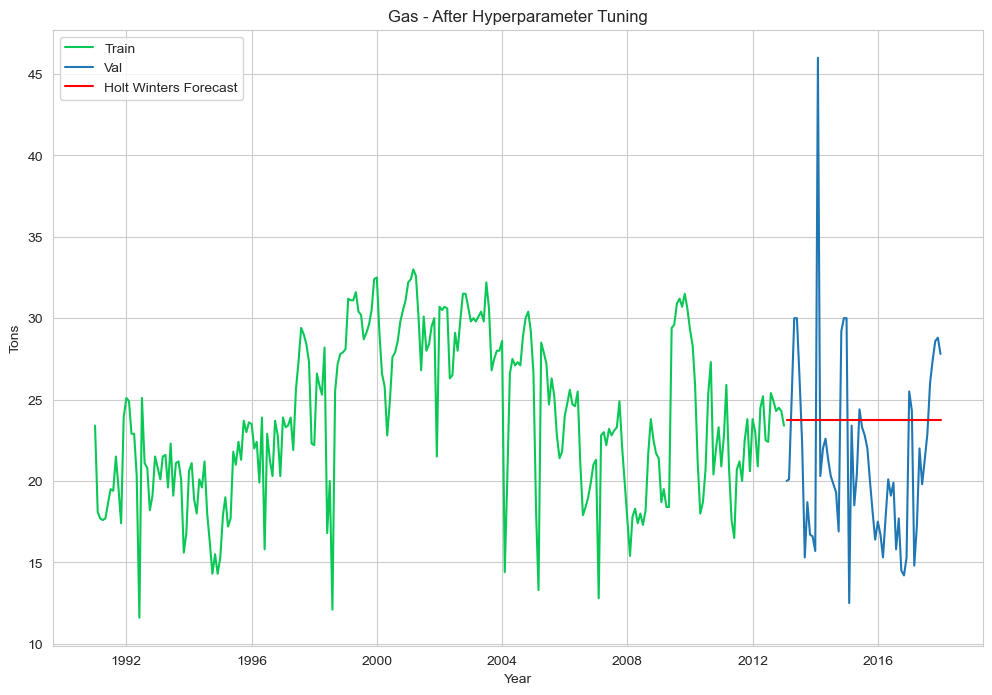

In [45]:
plt.figure(figsize=(12, 8))
plt.plot(gas_train, label="Train", color='#09C856')
plt.plot(gas_val, label='Val')
plt.plot(gas_val_pred, label="Holt Winters Forecast", color='#ff0000')
plt.title("Gas - After Hyperparameter Tuning")
plt.xlabel("Year")
plt.ylabel("Tons")
plt.legend()

plt.show()


### Electricity Forecasting

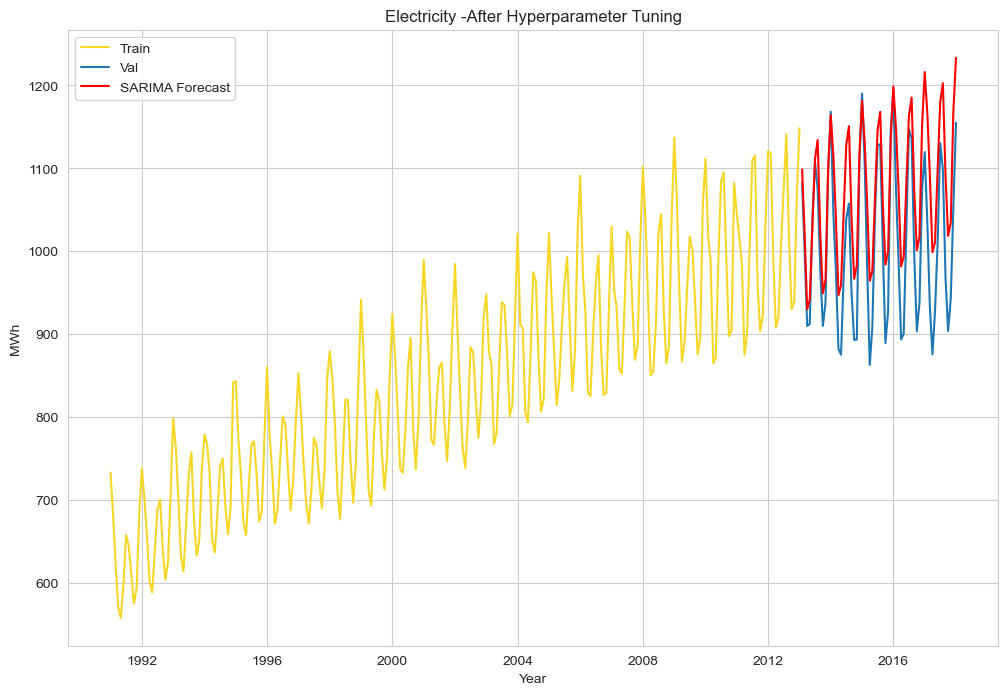

In [46]:
plt.figure(figsize=(12, 8))
plt.plot(elec_train, label="Train", color='#F6D728')
plt.plot(elec_val, label='Val')
plt.plot(elec_val_pred, label="SARIMA Forecast", color='#ff0000')
plt.title("Electricity -After Hyperparameter Tuning")
plt.xlabel("Year")
plt.ylabel("MWh")
plt.legend()
plt.show()


### Water Forecasting:


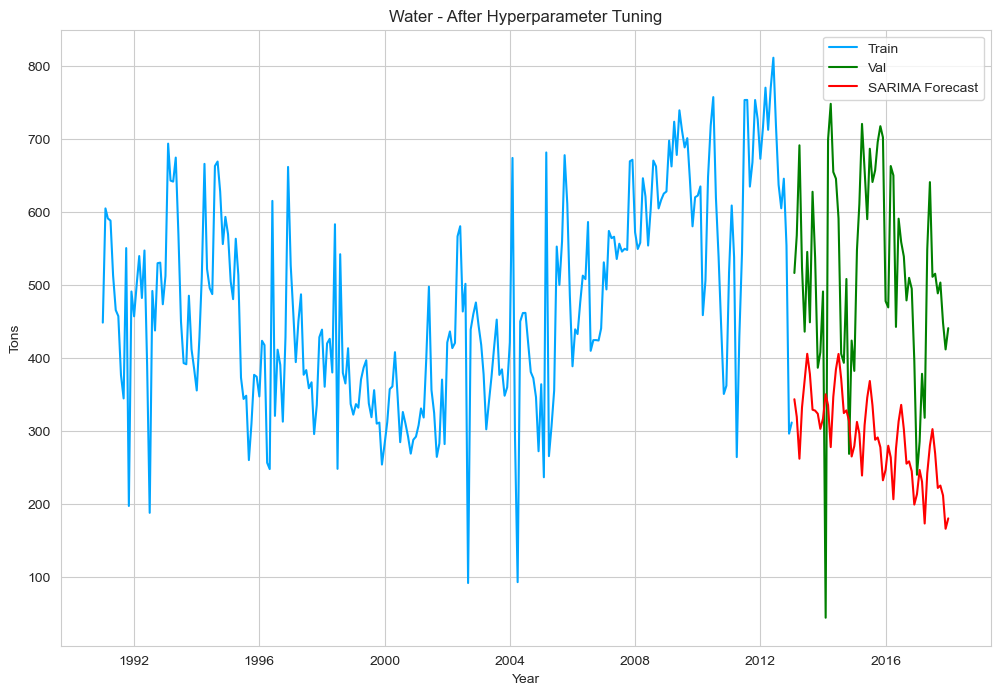

In [47]:
plt.figure(figsize=(12, 8))
plt.plot(water_train, label="Train", color='#00A6FF')
plt.plot(water_val, label='Val', color='green')
plt.plot(water_val_pred, label="SARIMA Forecast", color='#ff0000')
plt.title("Water - After Hyperparameter Tuning")
plt.xlabel("Year")
plt.ylabel("Tons")
plt.legend()
plt.show()


## **Key Insights Obtained:**

- ### **Gas:**
    - The tuned forecast becomes much flatter (nearly a straight line through validation).

    - Compared to before, it doesn’t follow the validation fluctuations (the up/down movement).

    - **What This Means:**
        - The tuned Holt-Winters settings likely damped the trend and smoothed seasonality too aggressively, so it predicts the “average level” rather than month-to-month variation.

    - **Conclusion:** Tuning made the model more stable, but less responsive, so it can underperform when the validation period is noisy.


- ### **Electricity:**
    - Electricity still shows strong seasonal waves, but after tuning the forecast can look phase-/amplitude-mismatched (waves don’t align perfectly with the validation section), and/or the forecast band appears to “sit” at a slightly off level.

    - **What This Means:**
        - Even if SARIMA captured the yearly pattern, the tuned parameters may have overfit to earlier folds (TimeSeriesSplit CV) or prioritised a better information criterion rather than matching the exact later behaviour.
    - **Conclusion:** Tuning kept seasonality, but didn’t necessarily improve alignment with the most recent period → explains why RMSE/MAE may not improve.


- ### **Water:**
    - The tuned forecast looks biased / drifting (e.g., trending down) while the validation actuals are highly volatile.

    - The after-forecast can miss the level and the spikes more strongly.

    - **What This Means:**
        - Water is the hardest series (lots of irregular jumps), so a tuned SARIMA that’s “too simple” or too differenced can lag behind and miss abrupt changes.

    - **Conclusion:** Tuning produced a model that is too smooth for a highly noisy series, so it visually underfits the validation behaviour.


## **Overall Conclusion:**
- Even though tuning can reduce AIC/BIC, the validation plots show weaker tracking of real movements (especially gas + water).

- Since the goal is forecasting future months, prioritise RMSE/MAE on validation, so you select the model that best matches the validation pattern, not just the best AIC/BIC.




--- 
# **Final Step: Evaluation of Model Performance On Test Set**
- Since the hyperparameter tuning returned models with a lower AIC/BIC but higher RMSE/MAE and considering that RMSE and MAE are our prioritising metrics for model evaluation, we will use the baseline models as our final models for each energy type consumption.


## **Finalised Models:**

- ### **Gas: Baseline Holt-Winters**

- ### **Electricity: Baseline SARIMA**

- ### **Water: Baseline SARIMA**


#### Next, we are going to plot out the forecasting of each model on the test set, which has not been used up until this step, in order to remove any bias by allowing the model to generalise on unseen data and hence evaluate its performance with it.

### **Gas Performance on Test Set**

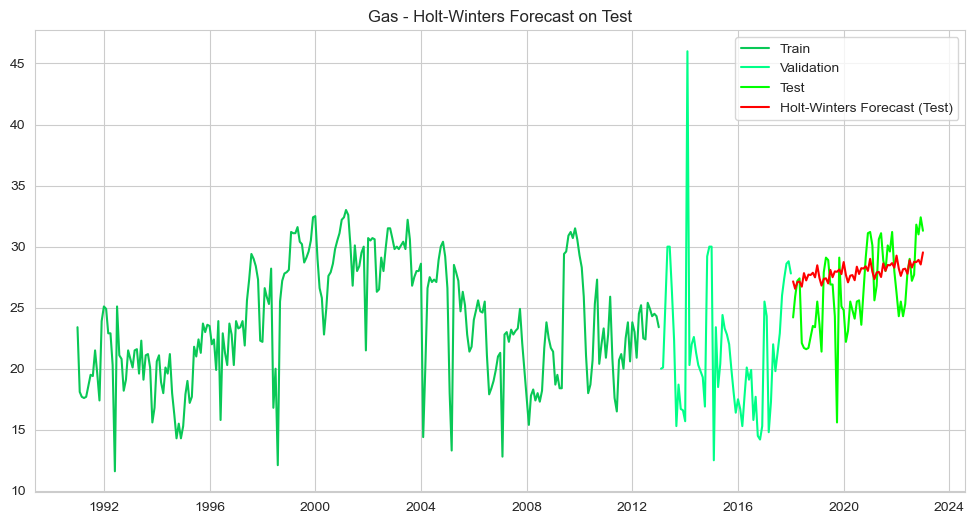

In [ ]:

train_val_gas = pd.concat([gas_train, gas_val])
final_gas_hw = ExponentialSmoothing(
    train_val_gas,
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

final_gas_pred = final_gas_hw.forecast(steps=len(gas_test))


plt.figure(figsize=(12,6))
plt.plot(gas_train, label="Train", color='#09C856')
plt.plot(gas_val, label='Validation', color="#00ff88")
plt.plot(gas_test, label="Test", color='#00ff00')
plt.plot(final_gas_pred, label="Holt-Winters Forecast (Test)", color='#ff0000')
plt.title("Gas - Holt-Winters Forecast on Test")
plt.legend()
plt.show()




### **Electricity Performance on Test Set:**

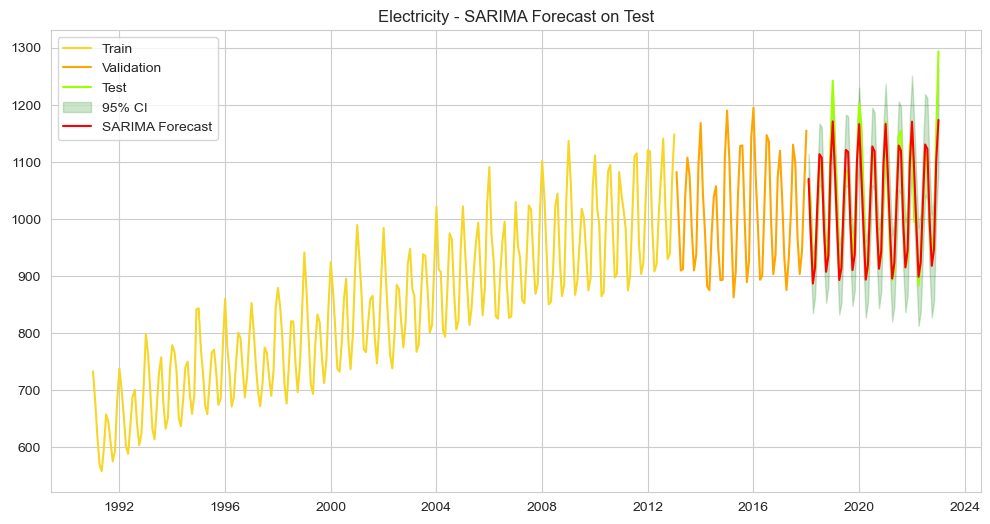

In [79]:
train_val_elec = pd.concat([elec_train, elec_val])
final_elec_sarima = SARIMAX(
    train_val_elec,
    order=(1, 1, 1),
    seasonal_order=(2, 1, 1, 12)
).fit()

fc_obj = final_elec_sarima.get_forecast(steps=len(elec_test))

final_elec_pred = fc_obj.predicted_mean
conf_int_test = fc_obj.conf_int()

final_elec_pred.index = elec_test.index
conf_int_test.index = elec_test.index


plt.figure(figsize=(12,6))
plt.plot(elec_train, label="Train", color='#F6D728')
plt.plot(elec_val, label='Validation', color='orange')
plt.plot(elec_test, label="Test", color="#9dff00")
plt.fill_between(
    elec_test.index,
    conf_int_test['lower Electricity Consumption (MWh)'],  # Adjust name as needed
    conf_int_test['upper Electricity Consumption (MWh)'],
    color="green",
    alpha=0.2,
    label="95% CI"
)

plt.plot(final_elec_pred, label="SARIMA Forecast", color='#ff0000')

plt.title("Electricity - SARIMA Forecast on Test")
plt.legend()
plt.show()


### **Water Performance on Test Set:**


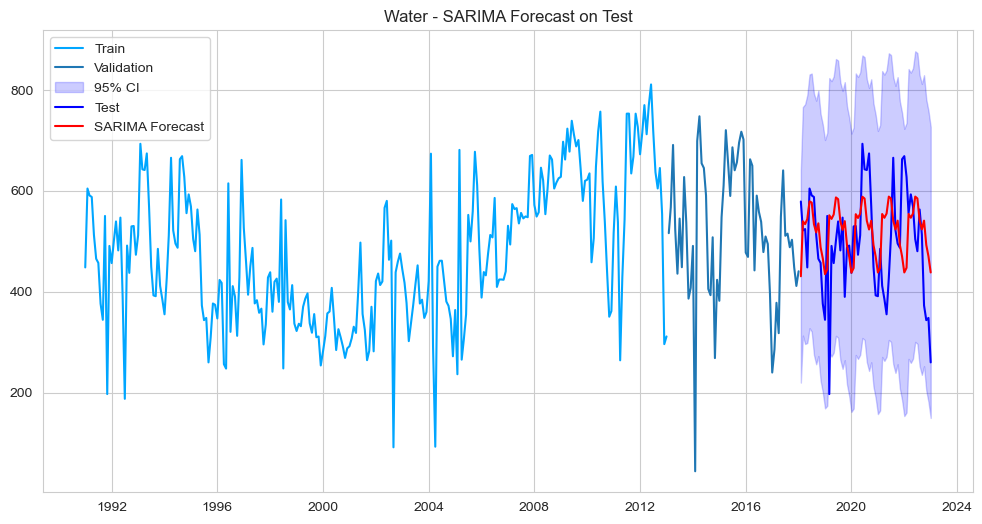

In [64]:
train_val_water = pd.concat([water_train, water_val])
final_water_sarima = SARIMAX(
    train_val_water,
    order=(1, 0, 1),
    seasonal_order=(0, 1, 1, 12)
).fit()

final_water_pred = final_water_sarima.forecast(steps=len(water_test))
fc_obj = final_water_sarima.get_forecast(steps=len(water_test))

final_water_pred = fc_obj.predicted_mean
conf_int_test = fc_obj.conf_int()


plt.figure(figsize=(12,6))
plt.plot(water_train, label="Train", color='#00A6FF')
plt.plot(water_val, label='Validation')
plt.fill_between(
    water_test.index,
    conf_int_test.iloc[:, 0],
    conf_int_test.iloc[:, 1],
    color="blue",
    alpha=0.2,
    label="95% CI"
)
plt.plot(water_test, label="Test", color="#0000ff")
plt.plot(final_water_pred, label="SARIMA Forecast", color='#ff0000')

plt.title("Water - SARIMA Forecast on Test")
plt.legend()
plt.show()


### **Some Insights:**
- **Gas:**
    - The Holt-Winters model captures the overall upward trend in gas consumption during the test period.

    - Forecast values remain close to the central range of actual observations.

    - However, short-term volatility and extreme spikes are not fully captured.

    - The model produces a relatively smooth forecast, indicating that it prioritises long-term structure over irregular fluctuations.

    - Despite some deviations, the forecast generally follows the direction of the actual test data.

**Overall:** Holt-Winters provides a stable and reasonable forecast for gas consumption, though it underreacts to sudden fluctuations.

- **Electricity:**  
    - The SARIMA model successfully captures the strong and consistent seasonal pattern in electricity consumption.

    - Forecasted peaks and troughs closely align with actual test observations.

    - Most test values fall within the 95% confidence interval, indicating reliable uncertainty estimation.

    - The amplitude and timing of seasonal cycles are well preserved.

    - Forecast deviation is minimal compared to gas and water.

**Overall:** SARIMA demonstrates strong generalisation performance for electricity, effectively modelling both trend and seasonal dynamics.

- **Water:**    
    - The SARIMA model captures the general seasonal structure of water consumption.

    - However, actual test values show higher irregularity and volatility.

    - The confidence interval is wider compared to electricity, reflecting increased uncertainty.

    - Several sharp drops and spikes are not precisely captured.

    - Forecast remains centred around the true consumption range despite variability.

**Overall:** While SARIMA models the underlying seasonal pattern reasonably well, water consumption exhibits greater unpredictability, leading to wider uncertainty bands and slightly reduced precision.

## **Final 60 Months Forecasting:**
- After evaluating the model’s performance on the test set and confirming its generalisation capability, the model is retrained using the full historical dataset.
- This forecast represents the model’s projection of future energy consumption based on the identified trend and seasonal patterns.

### **Gas Final Forecasting**

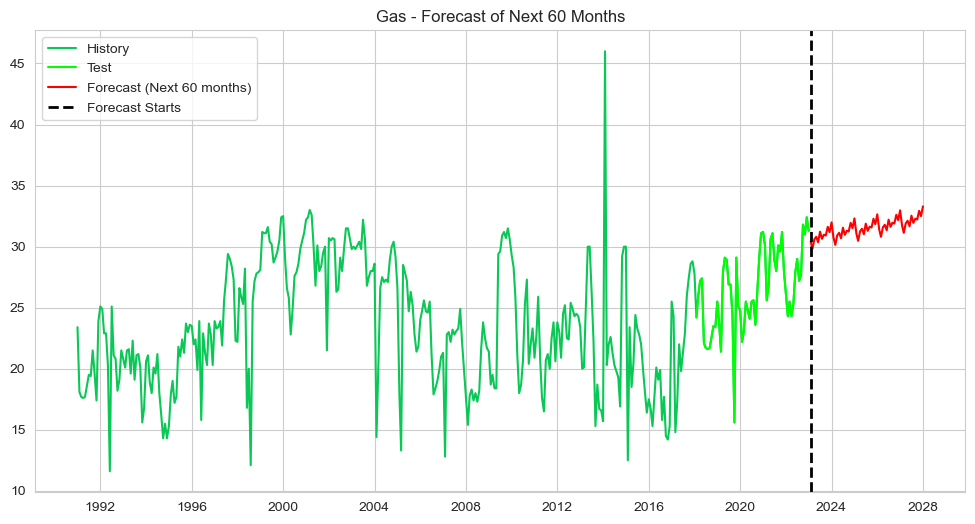

In [ ]:


final_gas_hw = ExponentialSmoothing(
    energy_df['Gas Consumption (tons)'],
    trend="add",
    seasonal="add",
    seasonal_periods=12
).fit()

final_gas_pred = final_gas_hw.forecast(steps=60)

future_index = pd.date_range(
    start=energy_df.index.max() + pd.offsets.MonthBegin(1),
    periods=60,
    freq="MS"
)

final_gas_pred.index = future_index

conf_int_test = final_gas_pred.conf_int()

plt.fill_between(
    gas_test.index,
    conf_int_test.iloc[:, 0],
    conf_int_test.iloc[:, 1],
    color="green",
    alpha=0.2,
    label="95% CI"
)

plt.figure(figsize=(12,6))
plt.plot(energy_df['Gas Consumption (tons)'], label="History", color='#09C856')
plt.plot(gas_test, label="Test", color='#00ff00')
plt.plot(final_gas_pred, label="Forecast (Next 60 months)", color='#ff0000')
plt.axvline(x=final_gas_pred.index[0], color="black", linestyle="--", linewidth=2, label="Forecast Starts")
plt.title("Gas - Forecast of Next 60 Months")
plt.legend()
plt.show()




### **Electricity Final Forecasting**

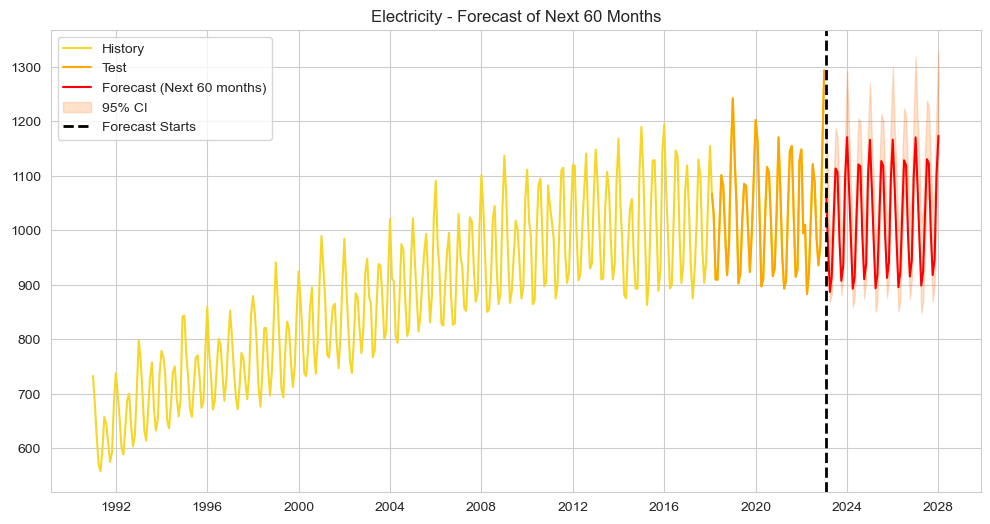

In [94]:
final_elec_sarima = SARIMAX(
    energy_df['Electricity Consumption (MWh)'],
    order=(1, 1, 1),
    seasonal_order=(2, 1, 1, 12)
).fit()

fc_obj = final_elec_sarima.get_forecast(steps=60)


conf_int_test = fc_obj.conf_int()


future_index = pd.date_range(
    start=energy_df.index.max() + pd.offsets.MonthBegin(1),
    periods=60,
    freq="MS"
)

final_elec_pred.index = future_index

conf_int_test.index = future_index

plt.figure(figsize=(12,6))
plt.plot(energy_df['Electricity Consumption (MWh)'], label="History", color='#F6D728')
plt.plot(elec_test, label="Test", color="orange")
plt.plot(final_elec_pred, label="Forecast (Next 60 months)", color='#ff0000')
plt.fill_between(
    future_index,
    conf_int_test.iloc[:, 0],
    conf_int_test.iloc[:, 1],
    color="#ff6a00",
    alpha=0.2,
    label="95% CI"
)

plt.axvline(x=final_elec_pred.index[0], color="black", linestyle="--", linewidth=2, label="Forecast Starts")
plt.title("Electricity - Forecast of Next 60 Months")
plt.legend()
plt.show()


### **Water Final Forecasting**

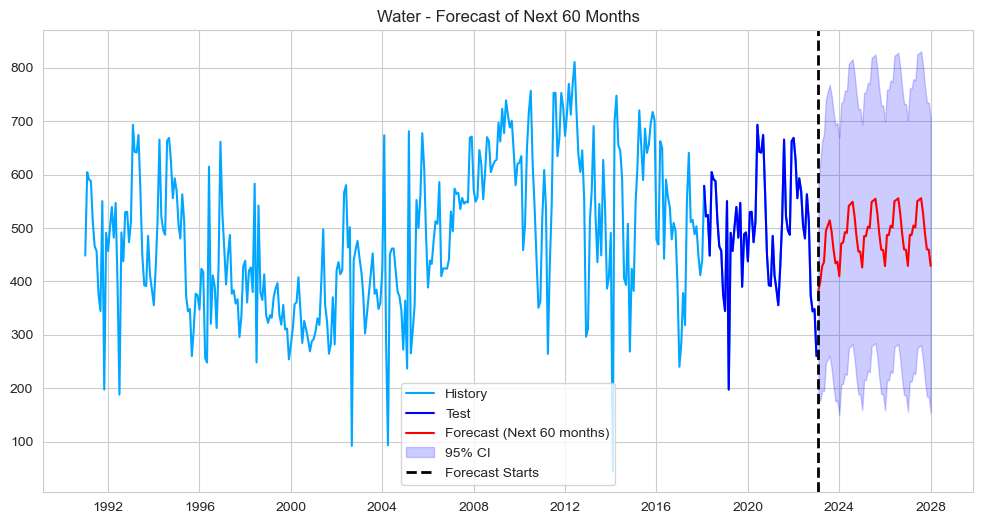

In [91]:
final_water_sarima = SARIMAX(
    energy_df['Water Consumption (tons)'],
    order=(1, 0, 1),
    seasonal_order=(0, 1, 1, 12)
).fit()

fc_obj = final_water_sarima.get_forecast(steps=60)

conf_int_test = fc_obj.conf_int()

future_index = pd.date_range(
    start=energy_df.index.max() + pd.offsets.MonthBegin(1),
    periods=60,
    freq="MS"
)

final_water_pred.index = future_index
conf_int_test.index = future_index

plt.figure(figsize=(12,6))
plt.plot(energy_df['Water Consumption (tons)'], label="History", color='#00A6FF')
plt.plot(water_test, label="Test", color='#0000ff')
plt.plot(final_water_pred, label="Forecast (Next 60 months)", color='#ff0000')
plt.fill_between(
    future_index,
    conf_int_test.iloc[:, 0],
    conf_int_test.iloc[:, 1],
    color="blue",
    alpha=0.2,
    label="95% CI"
)
plt.axvline(x=final_water_pred.index[0], color="black", linestyle="--", linewidth=2, label="Forecast Starts")
plt.title("Water - Forecast of Next 60 Months")
plt.legend()
plt.show()


### **Key Insights & Observations:**

- **Gas:**

    - The forecast suggests a gradual upward trend in gas consumption over the next 60 months.

    - Seasonal variation appears mild, indicating relatively stable demand patterns.

    - The model projects steady growth without extreme volatility.

    - Forecast fluctuations remain within a narrow range, suggesting moderate predictability.

    - No sharp structural changes are anticipated based on historical patterns.

- **Electricial:**

    - The forecast maintains a strong and consistent annual seasonal pattern.

    - Clear recurring peaks and troughs continue throughout the 60-month horizon.

    - The upward long-term trend persists, suggesting sustained growth in electricity demand.

    - The confidence interval gradually widens, reflecting increasing uncertainty over time.

    - Despite uncertainty, the seasonal amplitude remains structurally stable.

- **Water:**

    - The forecast preserves seasonal behaviour but shows greater variability compared to electricity.

    - Confidence intervals are noticeably wider, indicating higher uncertainty.

    - While seasonal cycles continue, amplitude appears less consistent.

    - The projected trend remains relatively stable without dramatic growth.

    - Volatility suggests water demand is more sensitive to external or irregular factors.



### **Interpretations:**

- **Gas:** Gas demand is expected to increase gradually with stable seasonal behaviour, indicating consistent long-term consumption growth.

- **Electricity:** Electricity consumption is projected to continue its upward trajectory with strong, predictable seasonal cycles, making it the most structurally stable series among the three.

- **Water:** Water consumption is expected to fluctuate seasonally but with higher uncertainty and variability, making long-term projections less precise compared to electricity.


--- 
# **Overall Forecasting Conclusion:**
The final forecasts indicate continued growth in energy demand over the next five years, though with varying levels of predictability.

  - **Electricity** shows the **`most stable`** and structured pattern, with **`strong`** and **`consistent seasonality`** maintained throughout the forecast horizon. 

  - **Gas** consumption is projected to **`increase gradually`** with relatively **`smooth fluctuations`**, indicating **`moderate stability`**. 

  - In contrast, **water** demand displays **`greater variability`** and **`wider confidence intervals`**, suggesting **`higher uncertainty`** in long-term projections.

Overall, while all three energy types are expected to maintain their general trends, forecasting uncertainty naturally increases further into the future, particularly for the more volatile series.


---
# **Summary of Part B:**
- ### **Importing Libraries and Modules:**
    - Imported essential libraries such as **`pandas, numpy, matplotlib, seaborn`** and time series modules including **`SARIMAX, ExponentialSmoothing, and TimeSeriesSplit`** from **`statsmodel`** library.
- ### **Dataset Loading:**
    - Loaded the energy consumption dataset containing Gas, Electricity, and Water consumption values from the file explorer.

- ### **Exploratory Data Analysis (EDA):**

    - Converted the time column into a proper **`DatetimeIndex`** to ensure correct time series handling.

    - Plotted histograms to view the distribution of energy consumptions and boxplot to analyse what the histogram is unable to cover (median, Interquartile range, etc).

    - Performed seasonal decomposition to analyse trend, seasonality, and residual components and plotted it.

- ### **Preprocessing:**
    
    - Conducted **`Visual Test`** and **`ADF Test`** to test for **`stationarity`** for each energy-type consumption. 

    - ### **Feature Engineering:** 

        - **`Added new columns`** to the dataset.

    - **`Simple Moving Average (SMA)`** applied to smooth short-term fluctuations using rolling window averaging, revealing underlying trends in energy consumption data.

    - Visualization of original versus SMA-smoothed data to compare raw patterns with trend lines.

    - Applied **`Seasonal Differencing`** (lag-12) to remove yearly patterns and achieve stationarity for time series modeling

    - Analyzed **`ACF/PACF`** plots of differenced data to determine appropriate SARIMA model parameters
    
- ### **Model Implementation:**

   - Split data into 3 sets: (Train, Validation, Test) via month splitting.

   - Implemented 4 Models:
   
        - ARIMA

        - SARIMA

        - AUTO-ARIMA

        - Holt-Winters

- ### **Model Evaluation:**

    - Calcualted **`Root Mean Squared Error (RMSE)`** and **`Mean Absolute Error (MAE)`** and displayed them in a pandas' DataFrame together with the **`Akaike Information Criterion (AIC)`** and **`Bayesian Information Criterion (BIC)`** score.

    - Chose **`Holt-Winters`** for **`Gas Consumption`** and **`SARIMA`** for both **`Electricity and Water Consumption`**.

- ### **Hyperparameter Tuning:**
    
    - Tuned the models by defining a function and incorporating **`TimeSeriesSplit`** in order to **`simulate`** a **`GridSearchCV`** effect to determine the best set of hyperparameters **`(order, seasonal_order)`**.

    - **Key Finding:** Tuned models achieved **`lower AIC/BIC scores`** but exhibited **`higher RMSE/MAE`** on validation data, indicating overfitting.

    - **Decision:** Selected **`baseline models`** over tuned versions, prioritizing predictive accuracy (RMSE/MAE) over model parsimony (AIC/BIC).

- ### **Model Performance on Test Set and Future Forecasting:**
    
    - **Test Set Validation:** Plotted forecasts with confidence intervals to evaluate model performance on unseen data before final deployment.

    - **Future Forecasting:** Generated 60-month predictions after confirming satisfactory test set accuracy.

---